# Instalar os programas e montar o google Drive

In [ ]:
!pip install pyabf
!pip install efel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.6/688.6 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.9/341.9 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.0/104.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


INFORMAR O CAMINHO PARA A PASTA ONDE ESTAO OS ARQUIVOS A SEREM ANALISADOS:


 OBS.: recomendo deixar este arquivo_de_codigo no msm local da pasta dos arquivos

In [ ]:
# '/content/drive/Shareddrives/SAMP-8 e SAMR-1/Registros Eletrofisiológicos'/ # folder antigo

In [ ]:
cd '/content/drive/MyDrive/Laboratorio Neurofisiologia/Projeto SAMP8/Registros Eletrofisiológicos'

/content/drive/.shortcut-targets-by-id/1lMJs6OOxMh_gEFC-2der6SB0a4NRFsG3/Laboratorio Neurofisiologia/Projeto SAMP8/Registros Eletrofisiológicos


Para verificar se o local esta correto:

In [ ]:
ls -li

total 16375
45 drwx------ 2 root root     4096 Aug 15  2024 '50-70 dias de idade SAMP-8 controle'/
49 drwx------ 2 root root     4096 Aug 16  2024 '7-8 meses de idade'/
50 -rw------- 1 root root  2178387 May  9  2025  ANALISES_ATIVAS_2025.ipynb
53 -rw------- 1 root root   700255 May 27  2025  ANALISES_FERNANDO_ATIVAS_3spikes_2nd_after_Reo.ipynb
52 -rw------- 1 root root   699677 May 26  2025  ANALISES_FERNANDO_ATIVAS_3spikes_first_after_REO.ipynb
54 -rw------- 1 root root 10899096 May 27  2025  ANALISES_PASSIVAS_2025_fernando.ipynb
56 -rw------- 1 root root  1622572 Mar 10 20:19  ANALISES_PASSIVAS_2026_Fernando.ipynb
48 -rw------- 1 root root   119451 Aug 15  2024 'CPF SAMP x SAMR.pzfx'
51 drwx------ 2 root root     4096 May  9  2025  Resultados_PAs_2025/
55 drwx------ 2 root root     4096 Mar 10 14:45  Resultados_PAs_2026/
47 -rw------- 1 root root   413568 Aug 15  2024 'SAMP8 Mice as a Model of Age-Related liu2020.pdf'
46 -rw------- 1 root root   115962 Aug 15  2024 'test de plastici

In [ ]:
import os
import efel
import pyabf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame, Series

# SAMP8: 2 meses

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['50-70 dias de idade SAMP-8 controle']

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['HPC - CPT-8',
                      'Cell HPC',
                      'Agonista A2a - CGS21680',
                      '100 Hz',
                      '10 Hz',
                      '50 Hz']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []
ListaPaTCH = []

ListaFiles = []

ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '50-70 dias de idade SAMP-8 controle/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 01 - Incomplete/24523000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
2, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 02/24523015.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
3, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 03/24523018.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 04 - Incomplete/24919011.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 25
5, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 05/24n21001.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 30
6, Analisando: 50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 06/24n21017.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
7, Anali

# SAMP8: 7-8 meses

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['7-8 meses de idade']  # , '50-70 dias de idade SAMP-8 controle'

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['SAMP-8_controle_adoR antag/CPT-8 100 nM', 'Agon. A2Ar 60nM', 'HPC whole cell/SAMP-8', '10 Hz - 50 pulses', '100 Hz - 50 pulses', '50 Hz/Controle']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []
ListaPaTCH = []

ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '7-8 meses de idade/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 01 - 500nM/24311000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
2, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 02 - 500 nM/24311012.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
3, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 03 - 500nM/24311027.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 04 - 100nM/24315037.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
5, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 05 - 100 nM/24315048.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
6, Analisando: 7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 06 - 100nM/24318000

# SAMP8: 7-8 meses Cafeina

In [ ]:
# Definir as pastas principais para análise
fldrs_principais = ['7-8 meses de idade/Cafeina']  # , '50-70 dias de idade SAMP-8 controle'

# Definir pastas a serem EXCLUÍDAS (nomes das pastas ou partes do caminho)
pastas_incluidas = ['ZM - Antag. A2AR',
                      'Agon. A2Ar 60nM',
                      'Antag. A1R 100nM',
                      '50 Hz',
                      'Patch HPC',
                      '10 Hz',
                      '100 Hz']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
full_folder_paths = []

Interneurons = []

ListaPaTCH = []


ii = 0
for pasta_principal in pastas_incluidas:
  grupo = '7-8 meses de idade/Cafeina/' + pasta_principal
  cellnumber = 0
  for cell in [fldrcell for fldrcell in sorted(os.listdir(grupo)) if '.' not in fldrcell]:
    for filename in sorted(os.listdir(grupo+'/'+cell))[0:3]:

      caminho_arquivo = grupo+'/'+cell+'/'+filename

      if 'Cell' in cell and grupo+'/'+cell not in ListaPaTCH:
                    try:
                        # print(f"Analisando: {caminho_arquivo}")
                        fileSize = os.path.getsize(caminho_arquivo)
                        if fileSize < 5000000:
                          abf = pyabf.ABF(caminho_arquivo)
                          if protocolo in abf.protocol and len(abf.sweepList) > 14  and "OLD" not in abf.protocol:
                              ii = ii + 1
                              print(f"{ii}, Analisando: {caminho_arquivo}, Protocolo: {abf.protocol}, Len SweepList: {len(abf.sweepList)}")
                              ListaPaTCH.append(grupo+'/'+cell)
                              ListaFiles.append(caminho_arquivo)
                    except:
                      pass


1, Analisando: 7-8 meses de idade/Cafeina/ZM - Antag. A2AR/Cell 01/24403022.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 26
2, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 01/24525030.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 23
3, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 02/24606000.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
4, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 03/24607002.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 25
5, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 04/24607010.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
6, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 05/24608009.abf, Protocolo: Long current step for pyramidal neurons_Allen, Len SweepList: 20
7, Analisando: 7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 

# Load all cells

In [ ]:
len(ListaFiles)

229

In [ ]:
import os
import efel
import pyabf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame, Series
from scipy.signal import find_peaks
import seaborn as sns
import scipy.stats as stats


50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 01 - Incomplete/24523000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


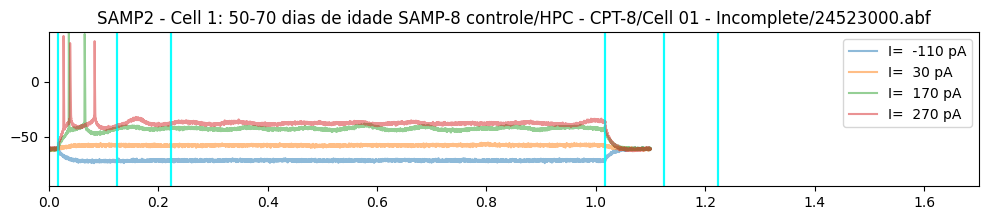

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 02/24523015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


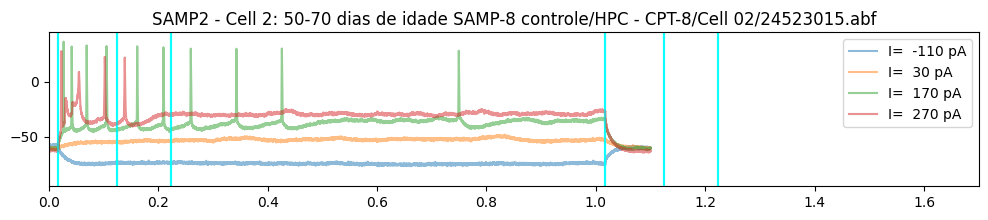

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 03/24523018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


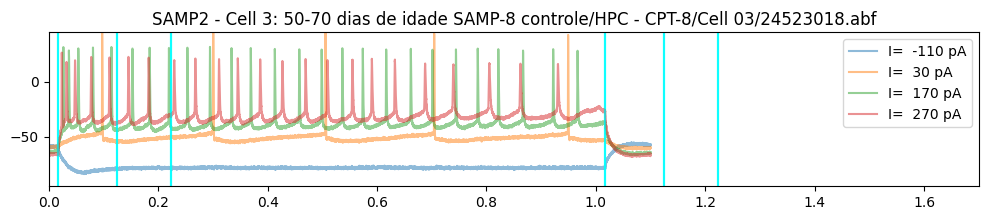

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 04 - Incomplete/24919011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


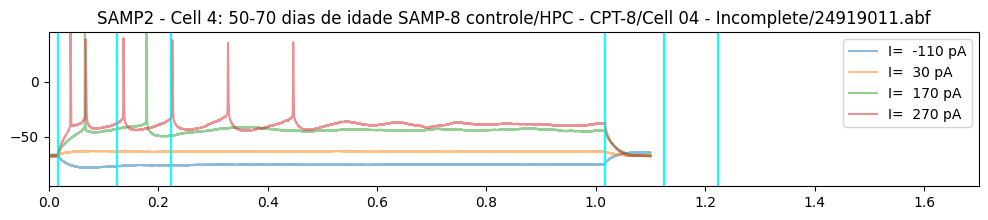

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 05/24n21001.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 06/24n21017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


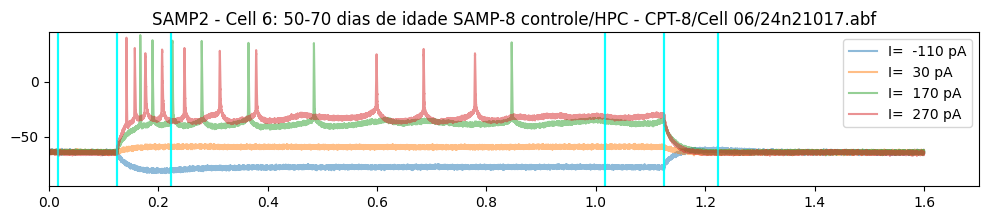

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 07/24n21013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 08/25415031.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


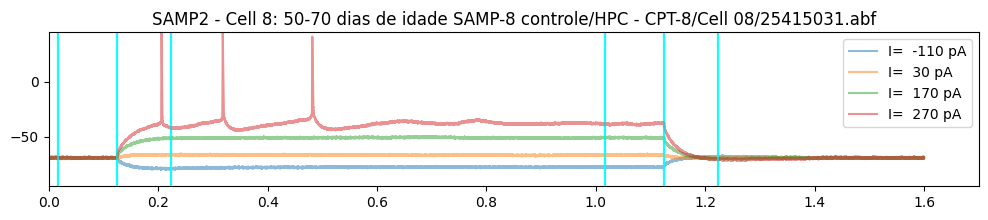

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 09/25417030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]


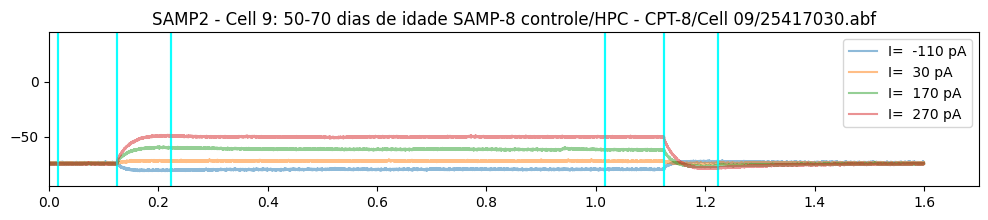

50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 10 /25418000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


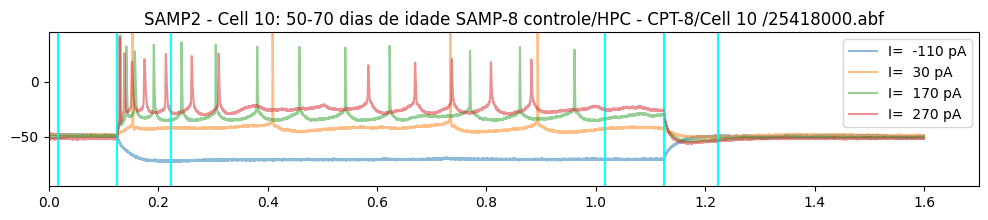

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 09/23516000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 10/23516014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


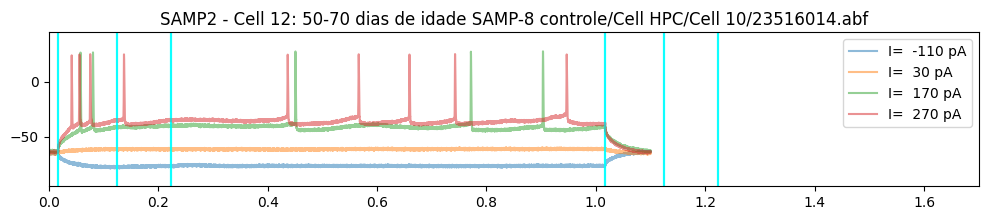

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 11/23517020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


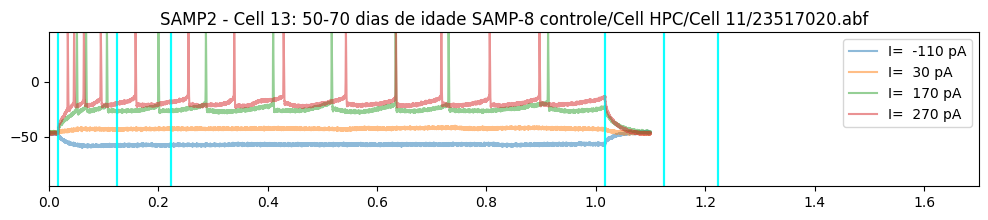

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 12/23519020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


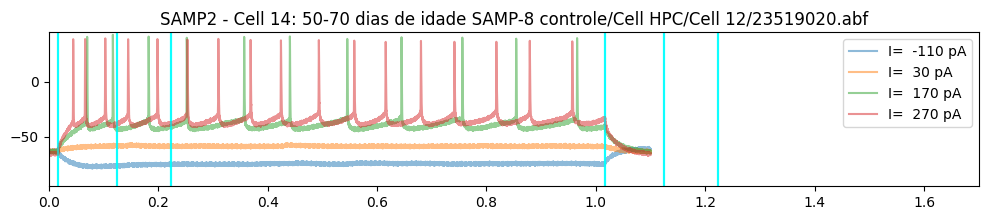

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 13/23519034.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


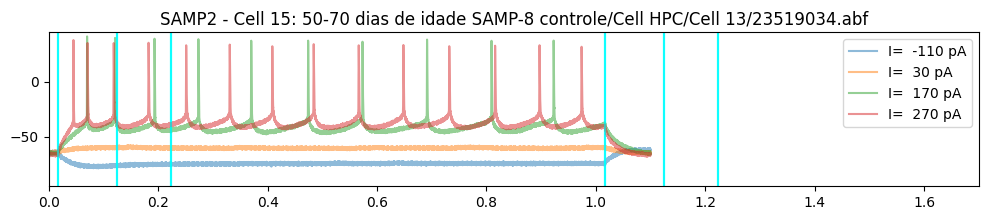

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 14/23520019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


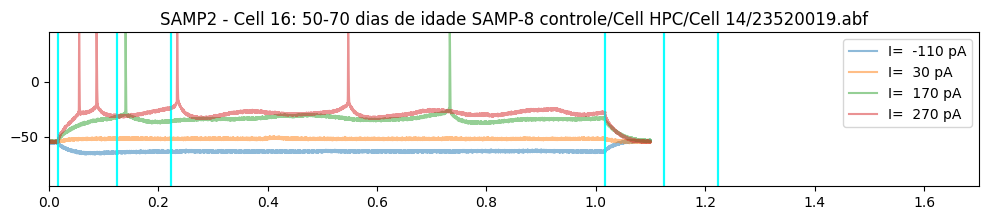

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 15/23520046 (1).abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


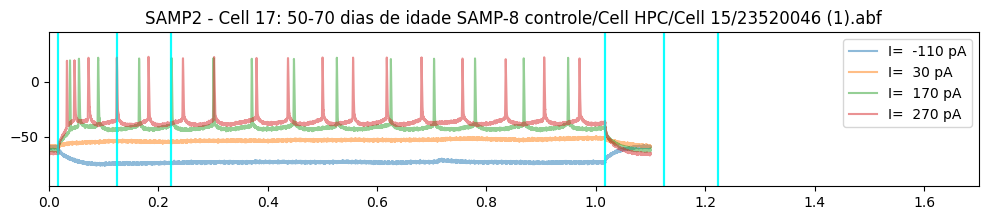

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 16/24523024.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


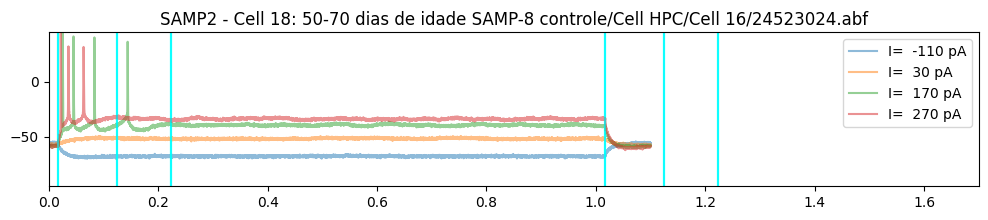

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 17/24523030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


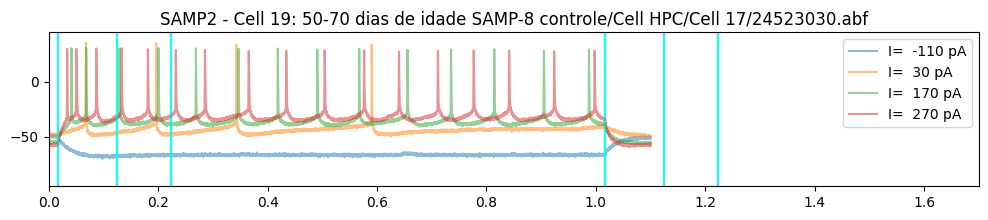

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 18/24528011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


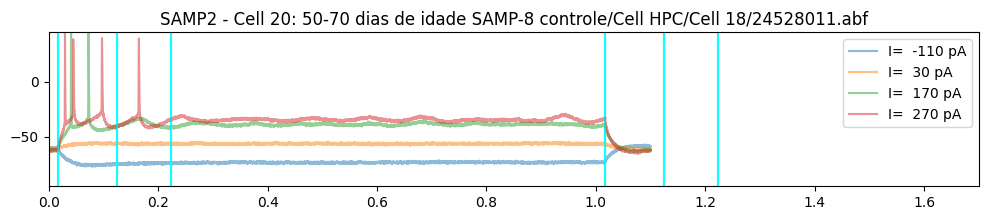

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 19/24919011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


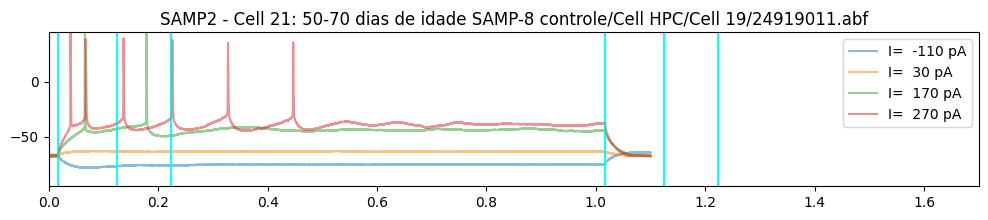

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 20/25616000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


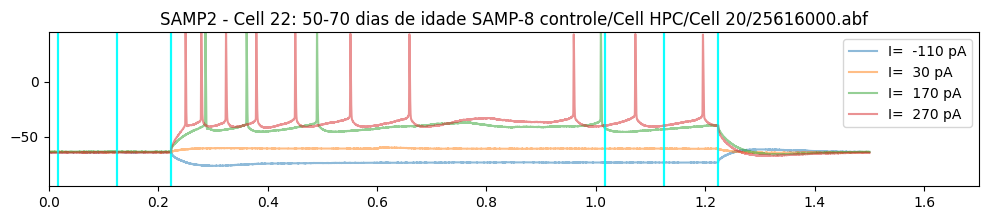

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 21/25617000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


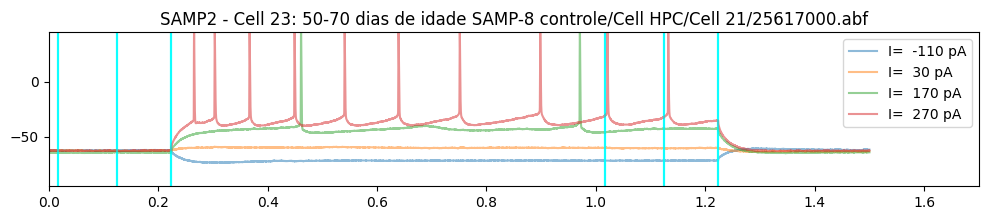

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 22/25616015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


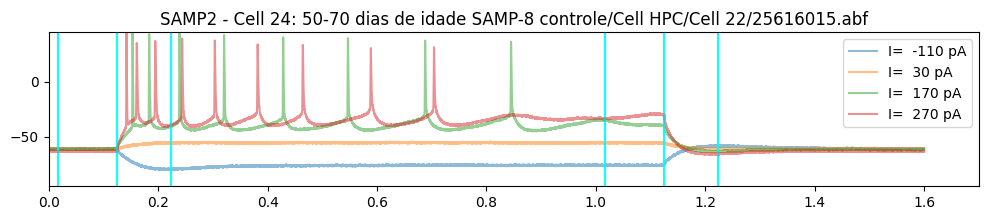

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 23/25616032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


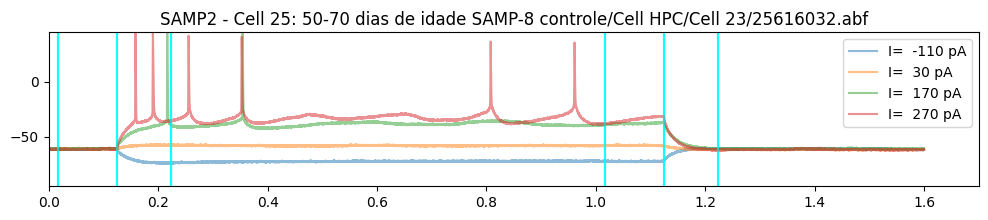

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 24/25617000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


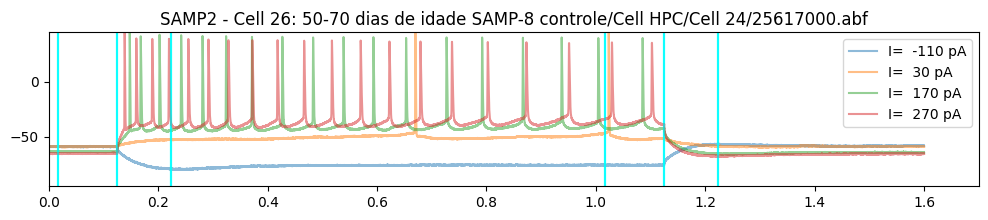

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 25/25617016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


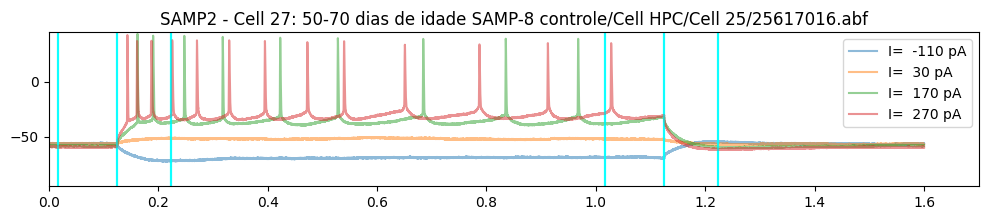

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 26/25617032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


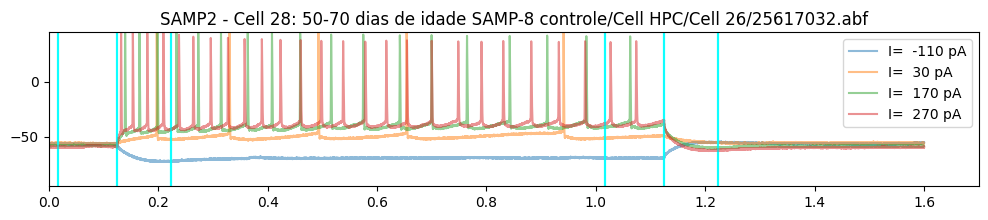

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 27/25617051.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


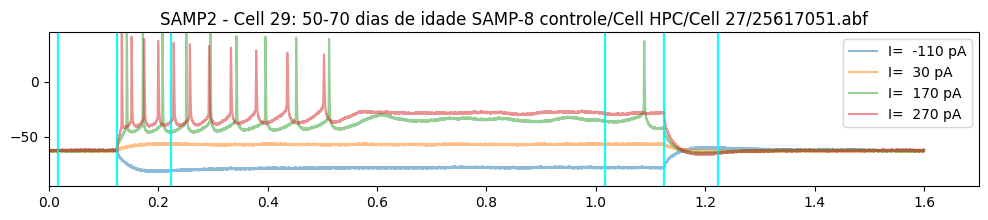

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 28/25617066.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


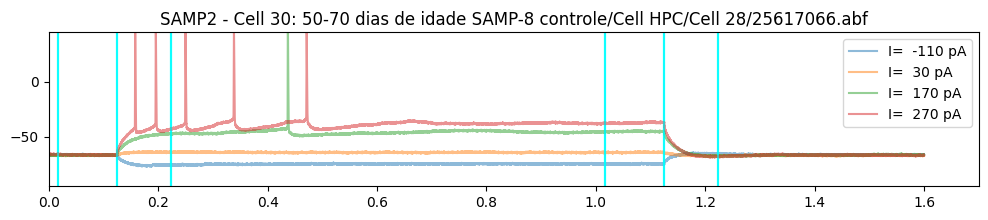

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 29/25617082.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


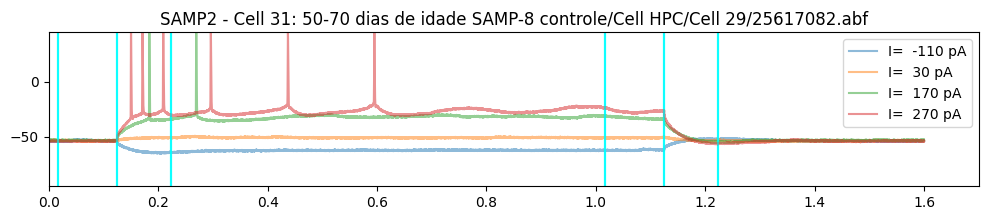

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 30/26305000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


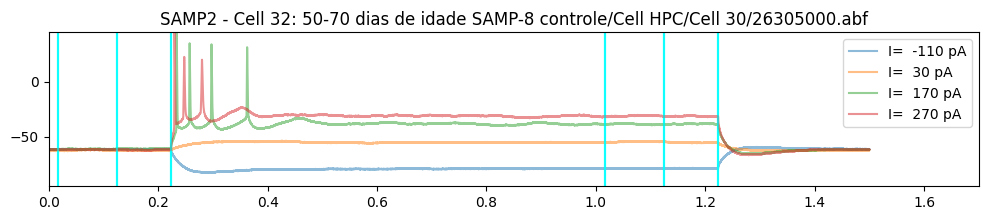

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 31/26305008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


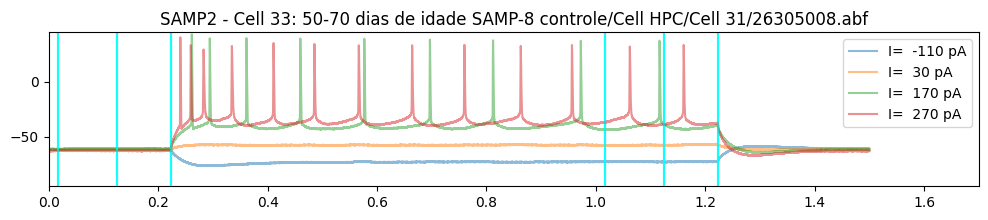

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 32/26305019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


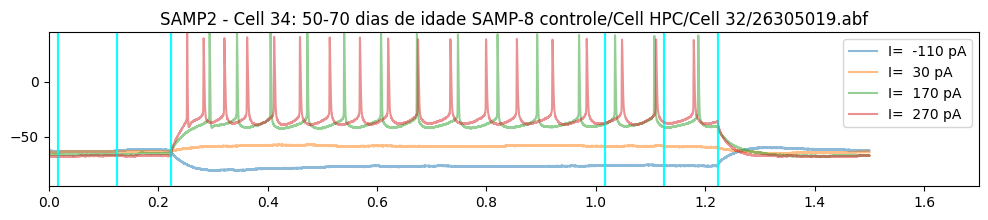

50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 33/26305032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


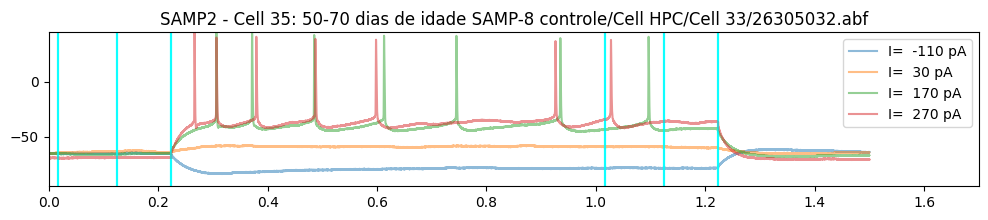

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 01/24919027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


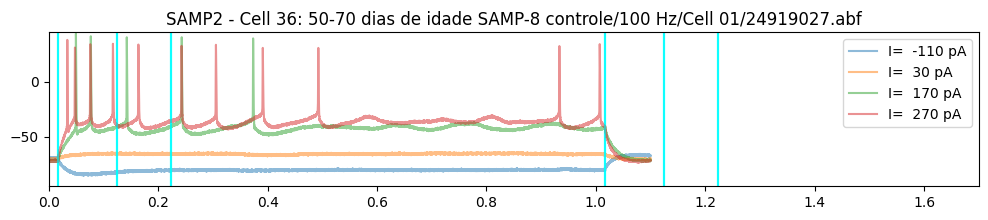

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 02/25311040.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


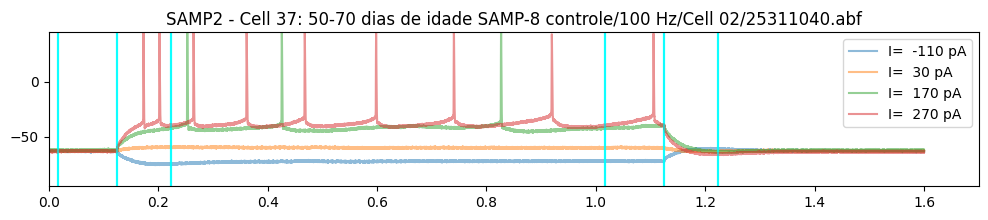

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 03 /25414002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


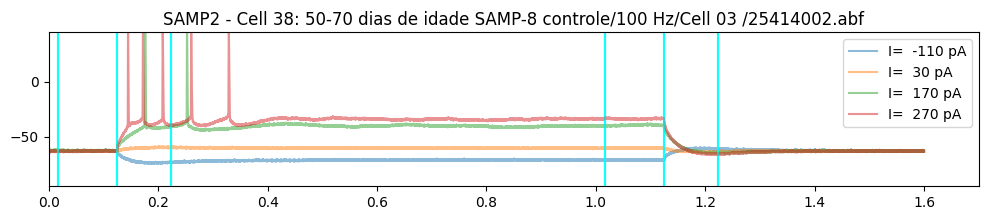

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 04/25415011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


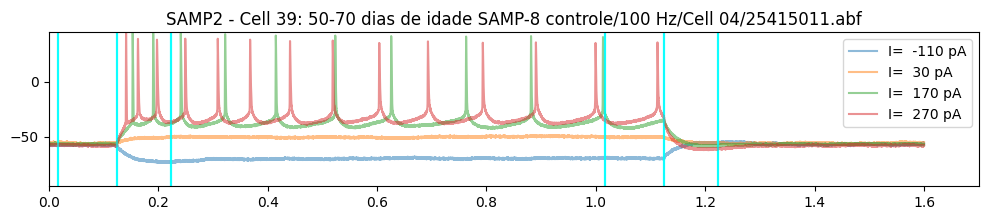

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 05/25415021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


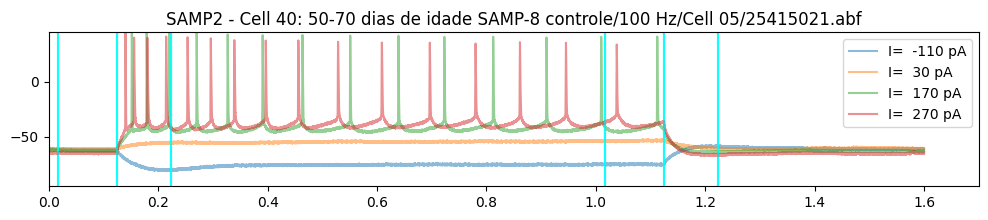

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 06/25417010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


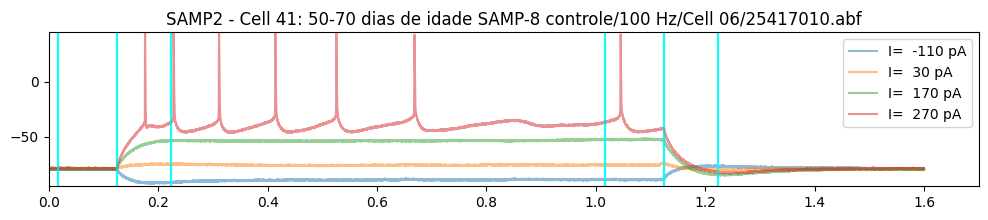

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 07/25417020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


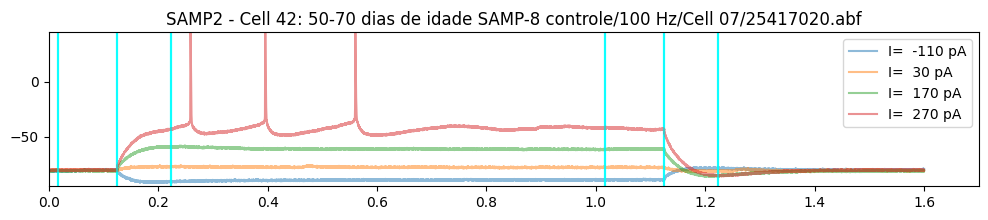

50-70 dias de idade SAMP-8 controle/100 Hz/Cell 08/25422000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


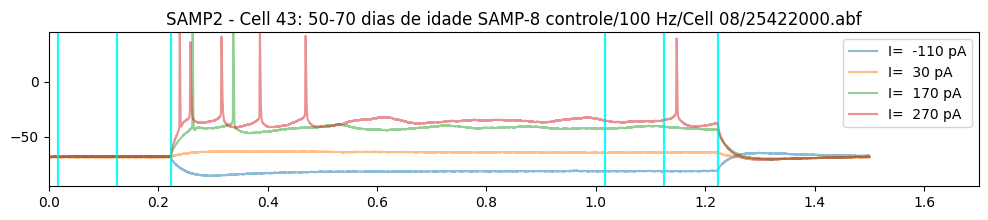

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 01/24919015.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


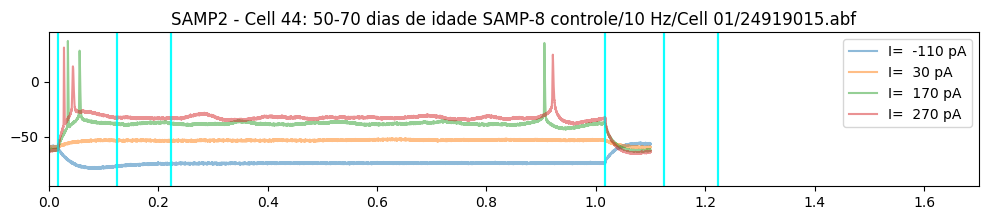

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 03/25311019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


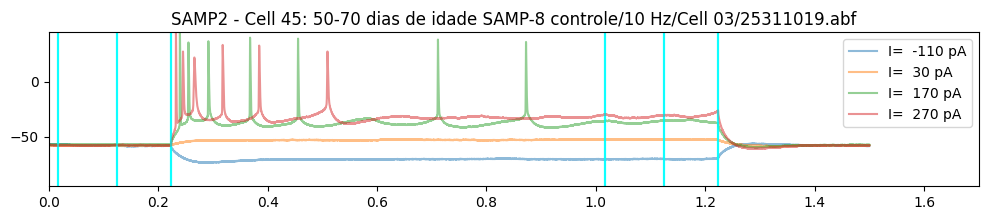

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 05/25415036.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


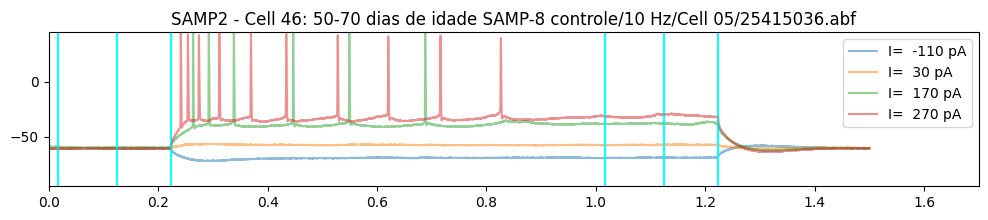

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 06/25417030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


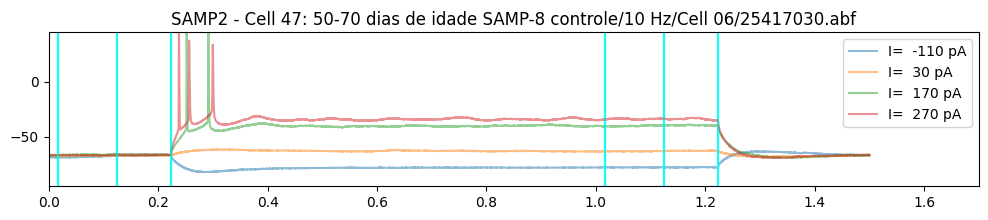

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 07/25418128.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


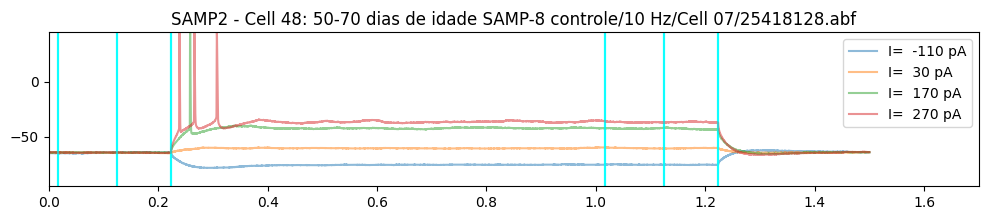

50-70 dias de idade SAMP-8 controle/10 Hz/Cell 08/25422004.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


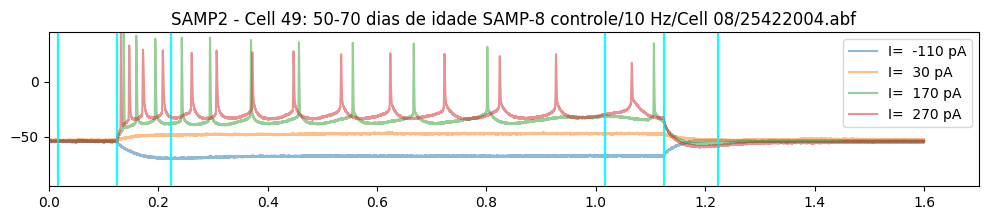

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 01/24523008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


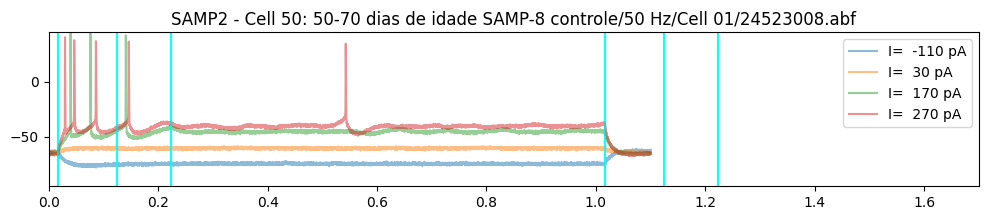

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 02/24523038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


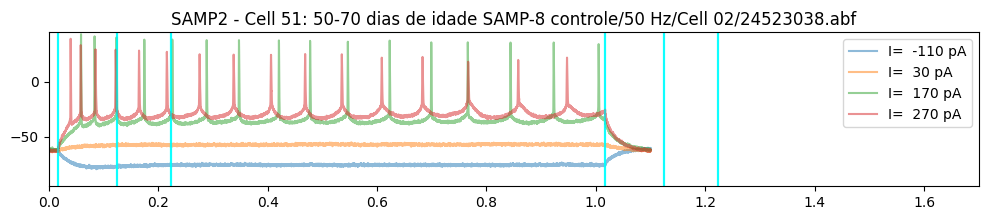

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 03 - Incomplete/24528000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


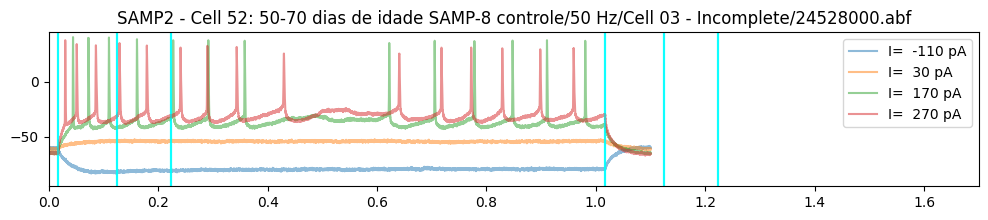

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 04/24528016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


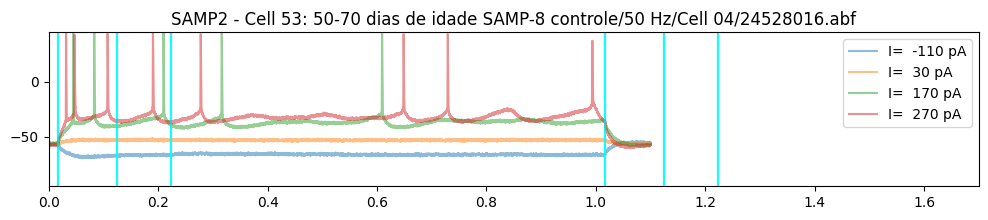

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 05/24919006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


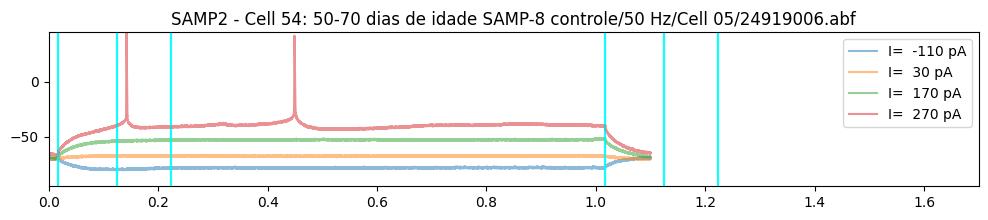

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 06/24n21007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


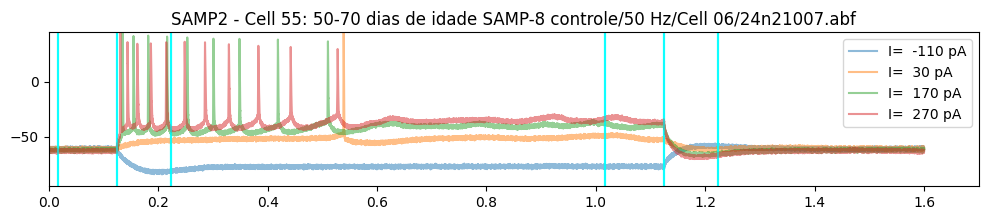

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 07/25113000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


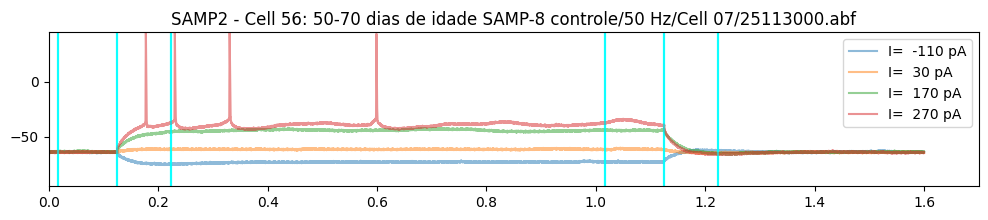

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 08 /25221009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


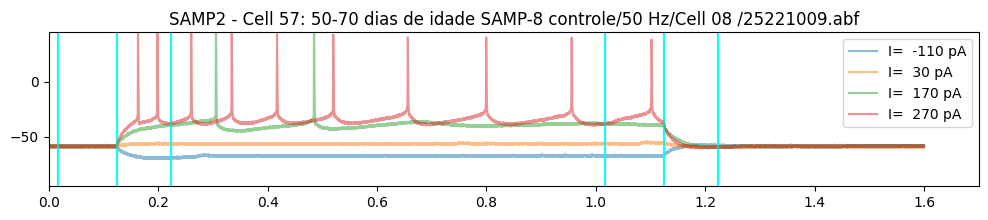

50-70 dias de idade SAMP-8 controle/50 Hz/Cell 09/25311000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 01 - 500nM/24311000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


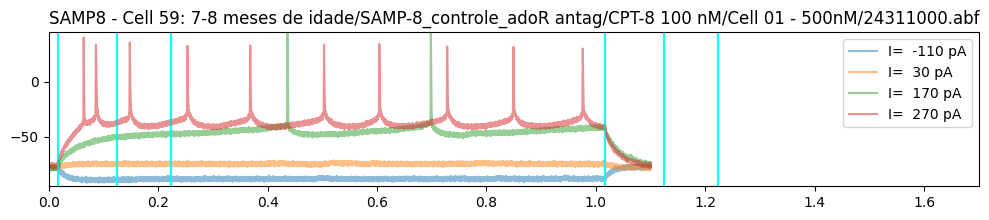

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 02 - 500 nM/24311012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


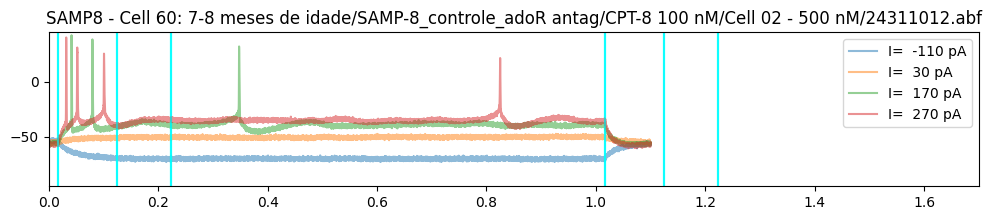

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 03 - 500nM/24311027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 04 - 100nM/24315037.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


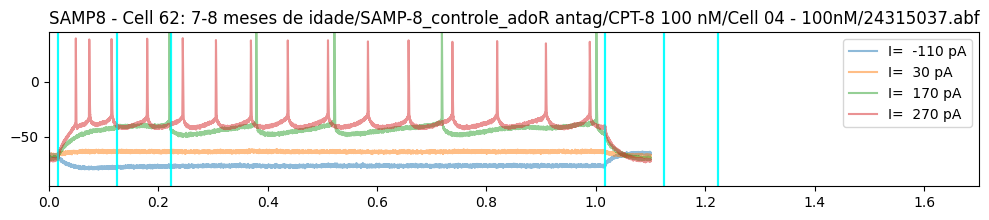

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 05 - 100 nM/24315048.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


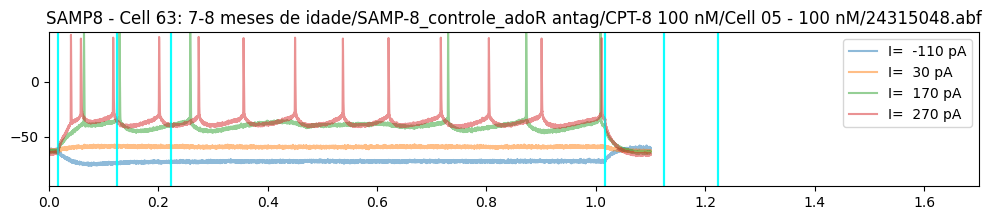

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 06 - 100nM/24318000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


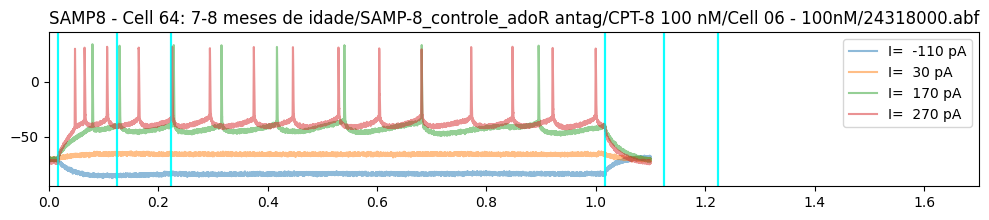

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 07 - 100nM/24318007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 08 - 100nM/24318013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


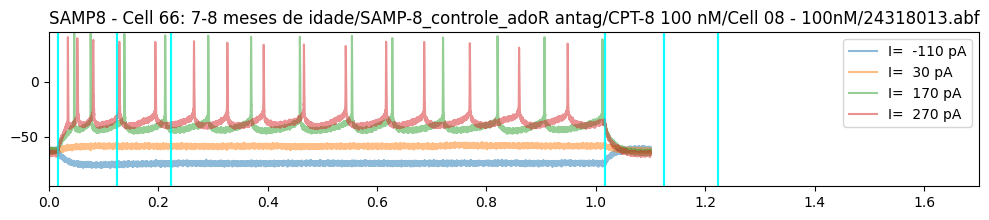

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 09 - 100nM/24318027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 10 - 100nM/24319014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


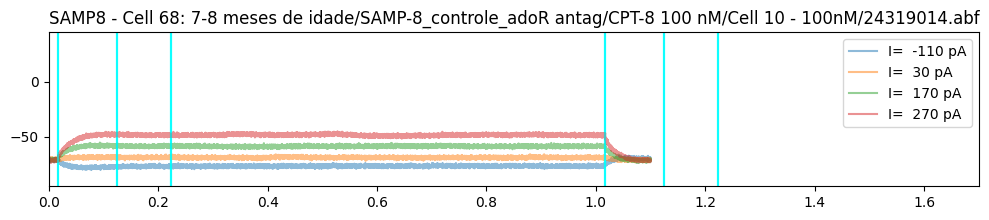

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 11 - 100nM/24319035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 12 - 100&500nM/24320007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


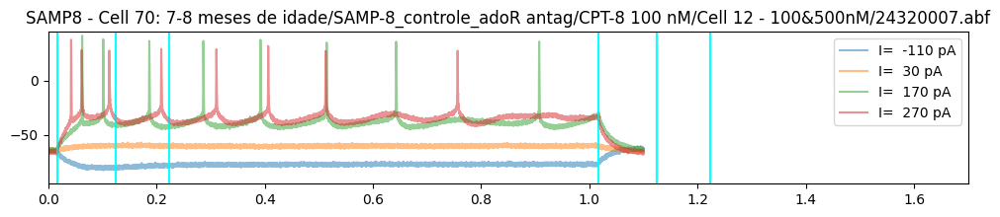

7-8 meses de idade/SAMP-8_controle_adoR antag/CPT-8 100 nM/Cell 13 - 500nM/24320025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


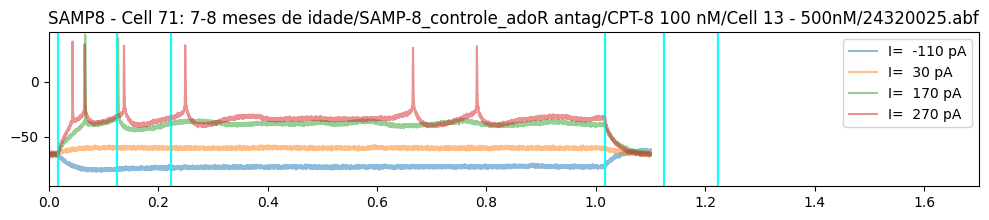

7-8 meses de idade/Agon. A2Ar 60nM/Cell 01/24618007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Agon. A2Ar 60nM/Cell 02/25403000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


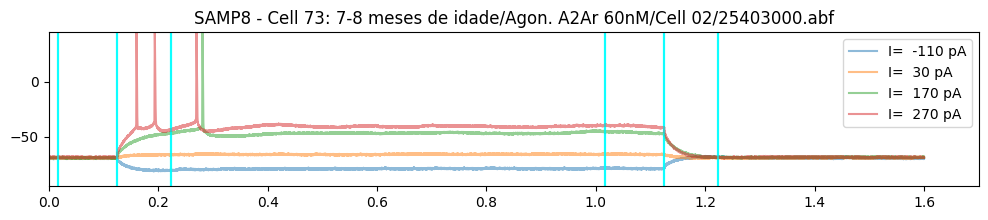

7-8 meses de idade/Agon. A2Ar 60nM/Cell 03/25403038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


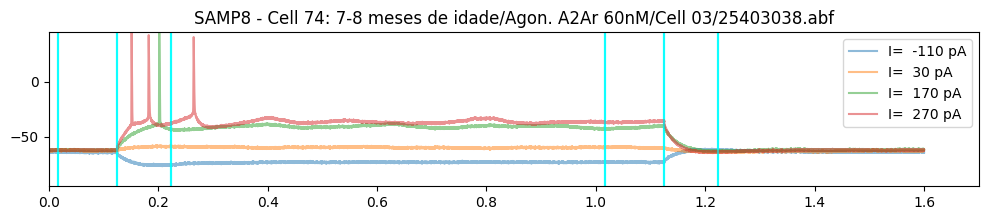

7-8 meses de idade/Agon. A2Ar 60nM/Cell 04/25404007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


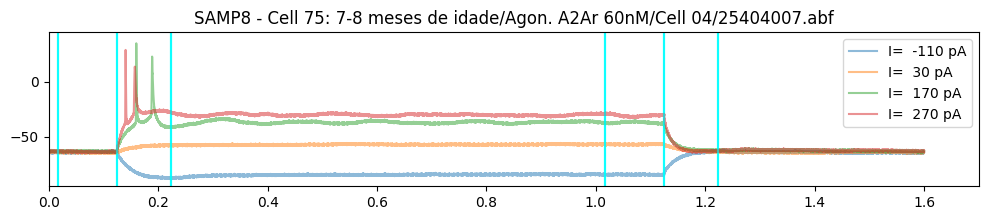

7-8 meses de idade/Agon. A2Ar 60nM/Cell 05/25410006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


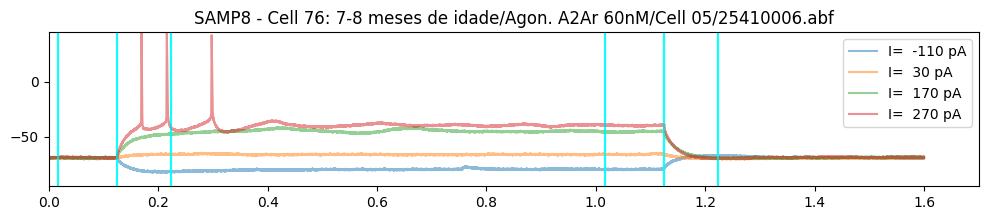

7-8 meses de idade/Agon. A2Ar 60nM/Cell 06/25411018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


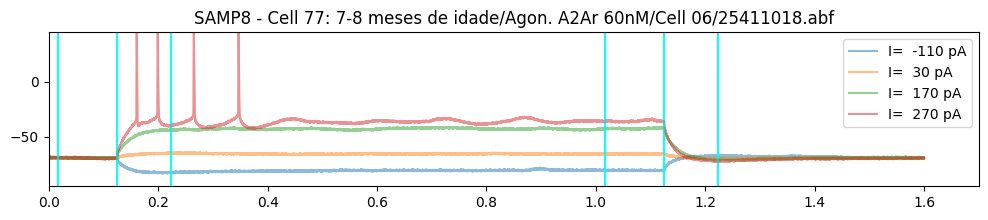

7-8 meses de idade/Agon. A2Ar 60nM/Cell 07 /25411010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


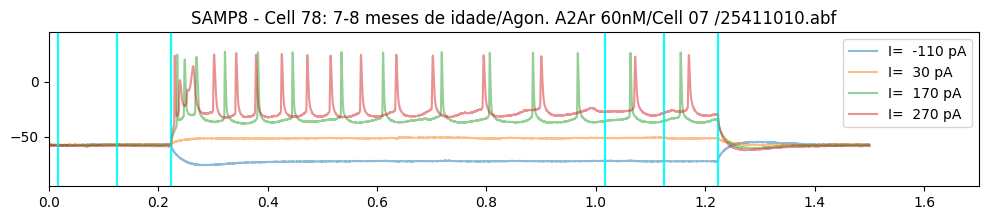

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 02/23424035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


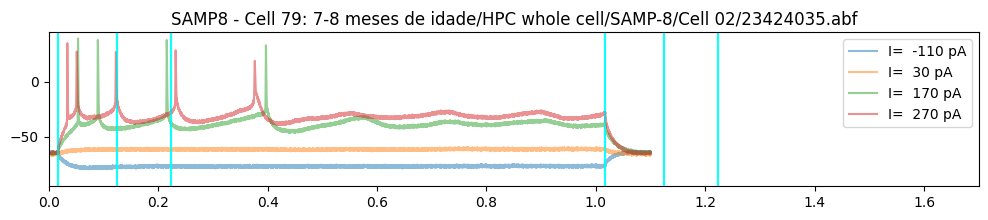

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 04/23425000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


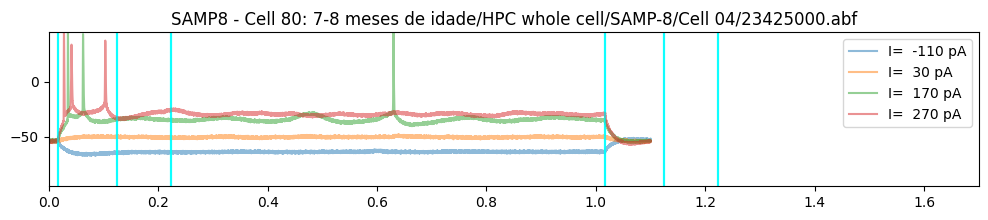

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 05/23425009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


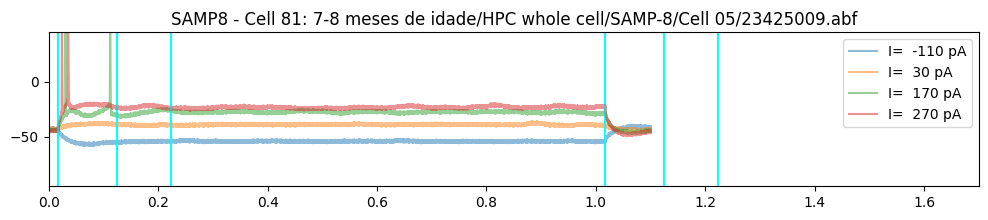

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 07/23d15000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


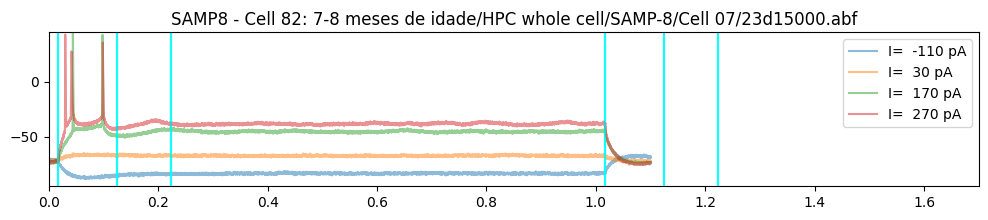

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 08/23d15014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


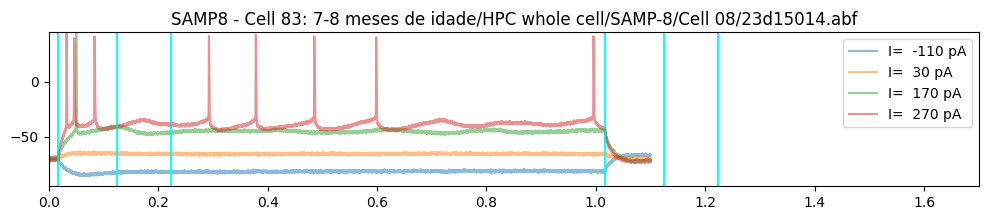

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 09/23d15025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


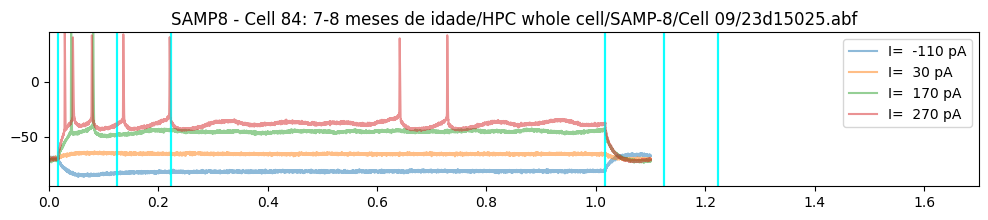

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 10/23d15040.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


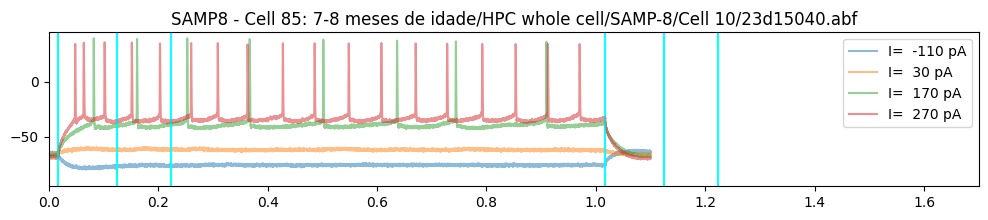

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 12/23d15075.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


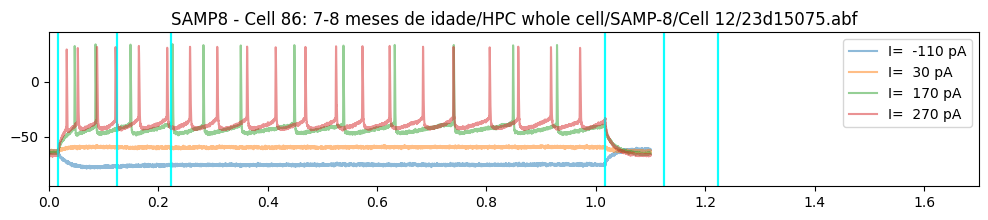

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 13/23d16010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


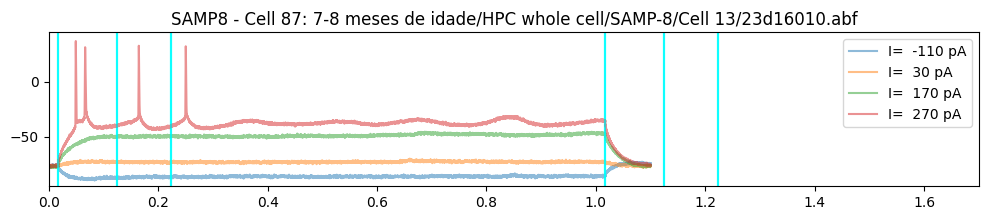

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 14/23d16013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


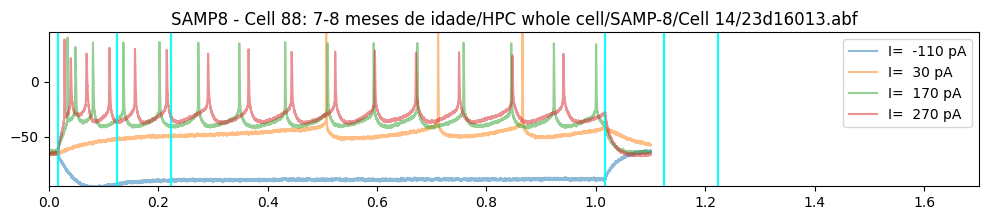

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 15/23d16021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


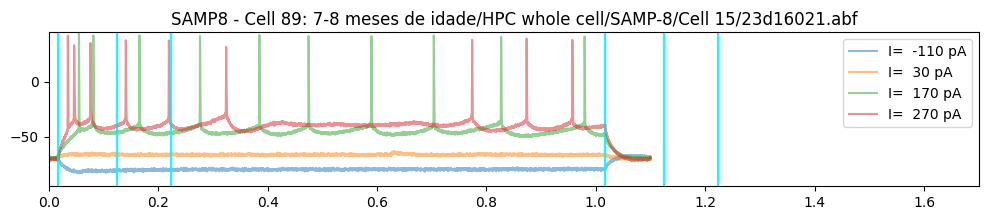

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 16/23d16029.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


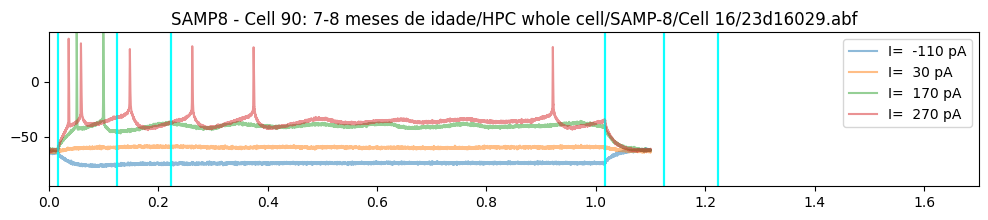

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 17/23d16038.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


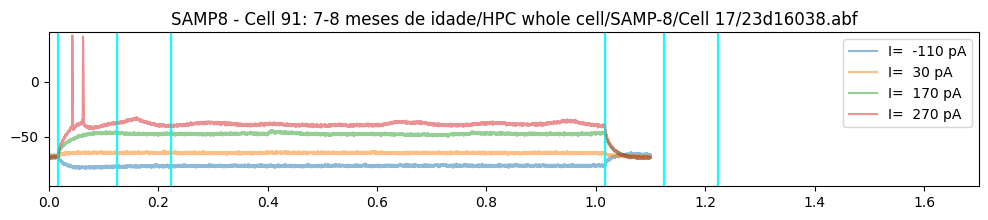

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 18/23d16053.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


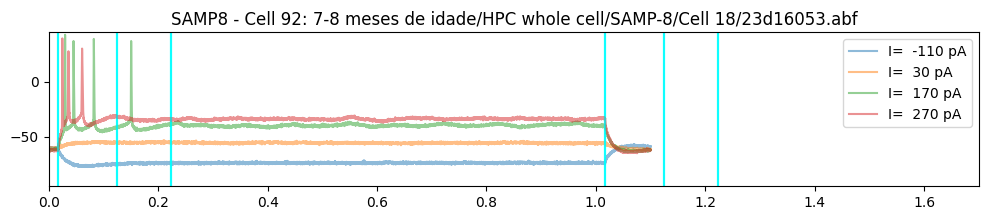

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 19/23d19000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


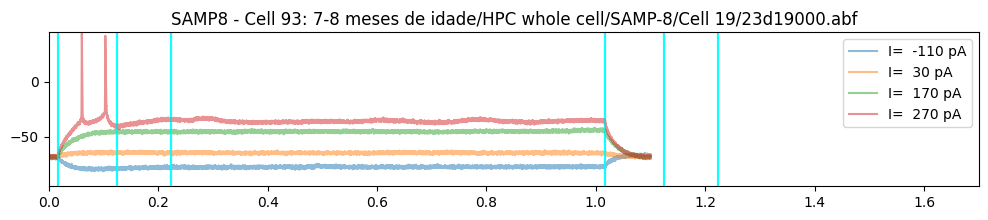

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 20/23d19016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


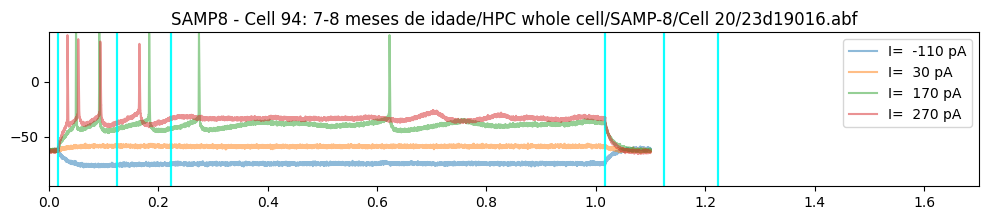

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 21/23d19035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


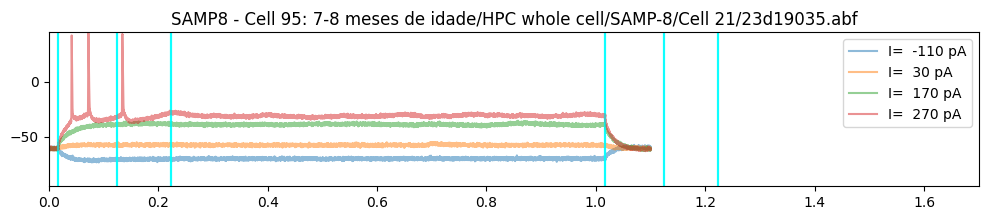

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 22/23d19050.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


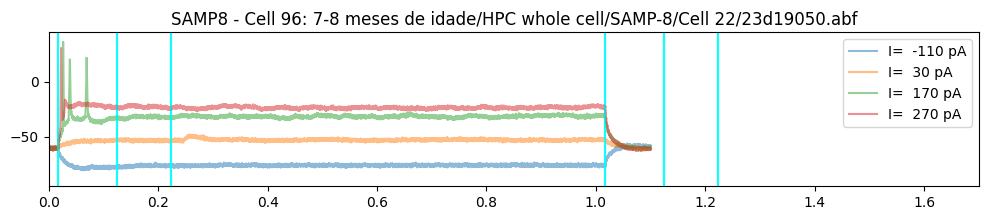

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 23/23d21000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 24/23d21007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 25/23d21012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 26/23d21027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 27/24311020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 28 - Incomplete/24517006.abf Long current step for 

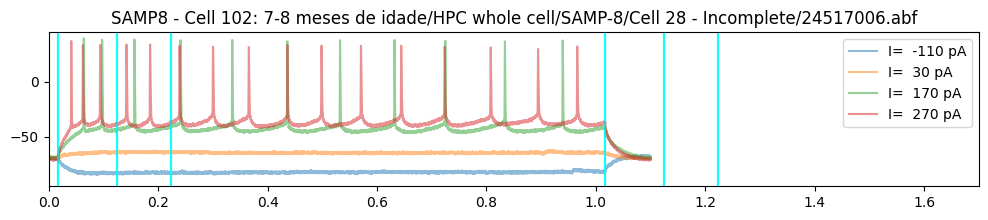

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 29 - Incomplete/24517011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


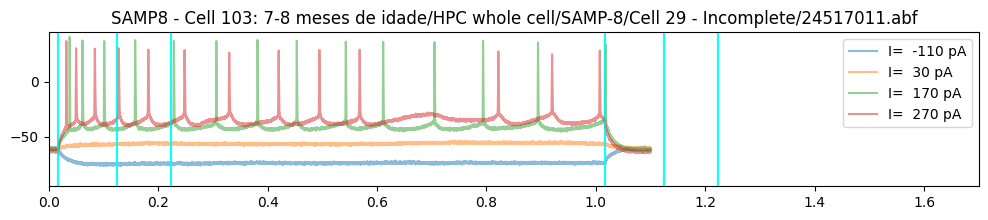

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 30 - Incomplete/24517014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 31/24520008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


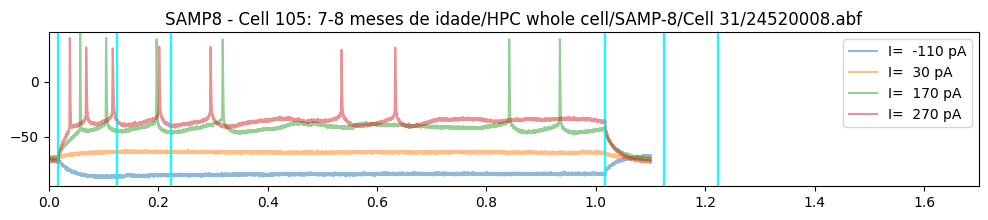

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 32/24520013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


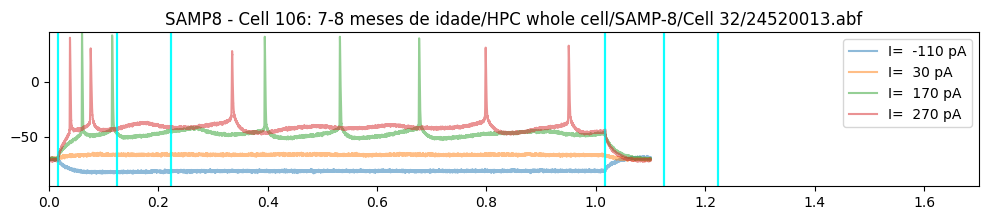

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 33/24520018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


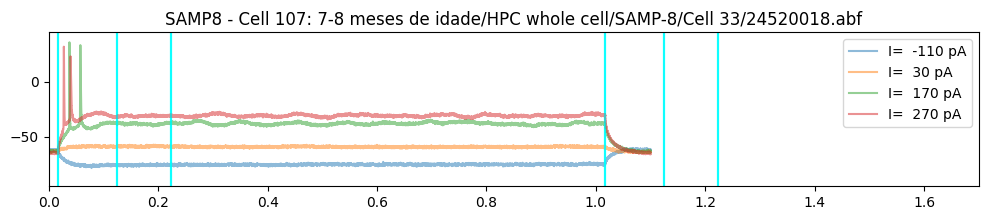

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 34/24521008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


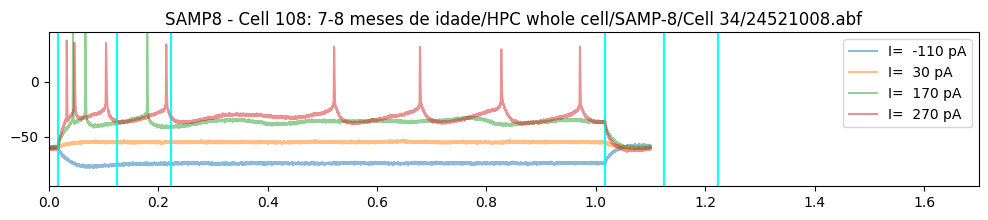

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 35/24521014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


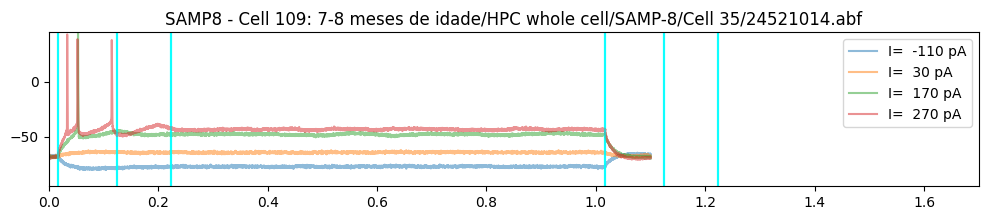

7-8 meses de idade/HPC whole cell/SAMP-8/Cell 36/24618000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/HPC whole cell/SAMP-8/Cell 37/24618002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/10 Hz - 50 pulses/Cell 01/25313045.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


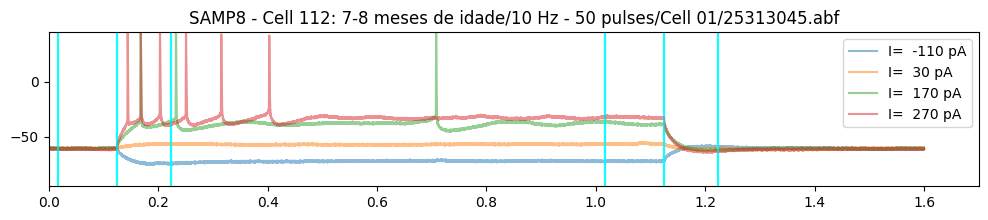

7-8 meses de idade/10 Hz - 50 pulses/Cell 02/25324034.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


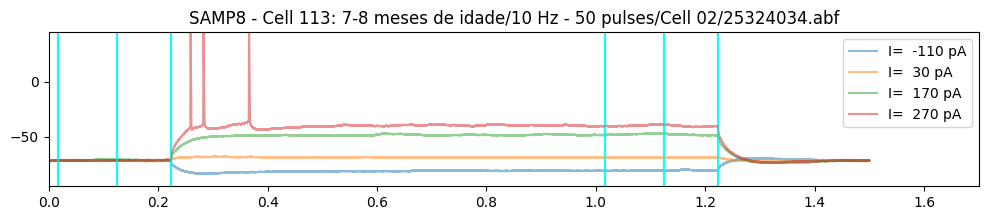

7-8 meses de idade/10 Hz - 50 pulses/Cell 03/25324049.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


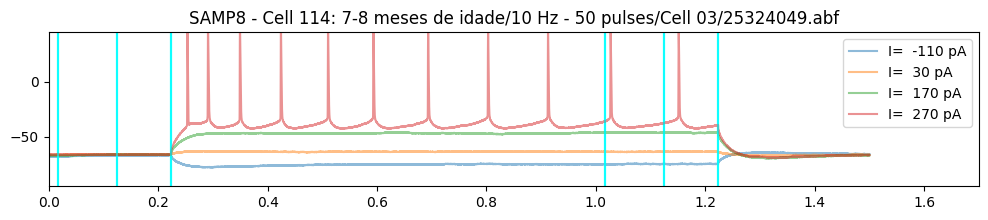

7-8 meses de idade/10 Hz - 50 pulses/Cell 04/25325000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


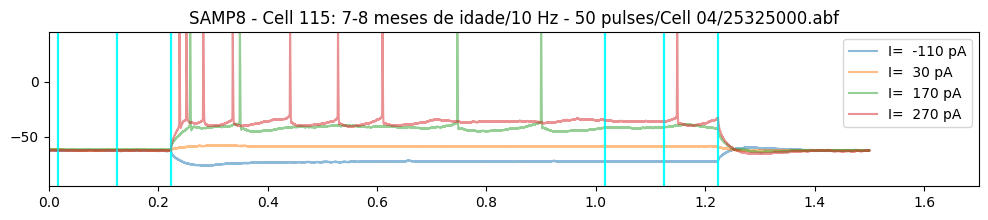

7-8 meses de idade/10 Hz - 50 pulses/Cell 05/25328006.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


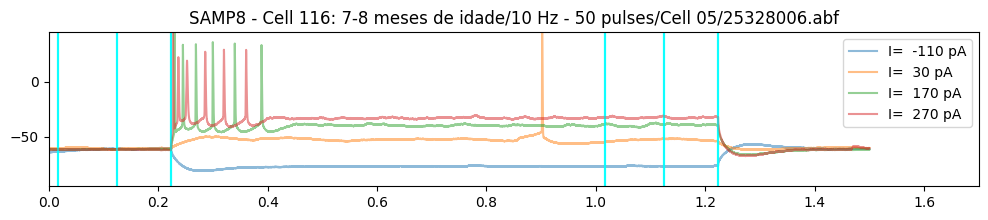

7-8 meses de idade/10 Hz - 50 pulses/Cell 06/25328023.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


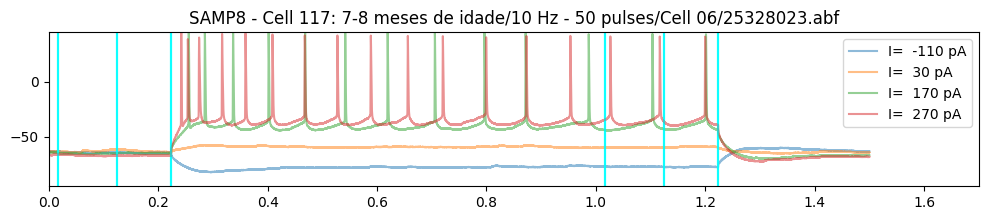

7-8 meses de idade/10 Hz - 50 pulses/Cell 07/25403021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


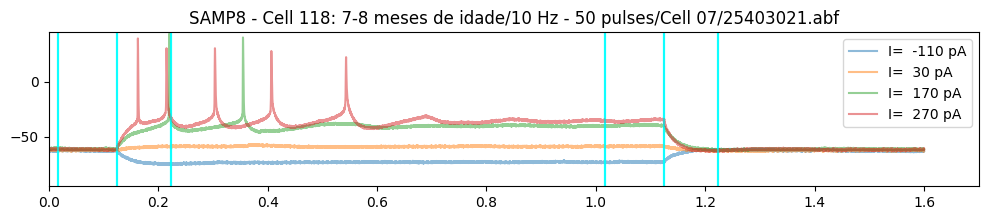

7-8 meses de idade/10 Hz - 50 pulses/Cell 08 /25403000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


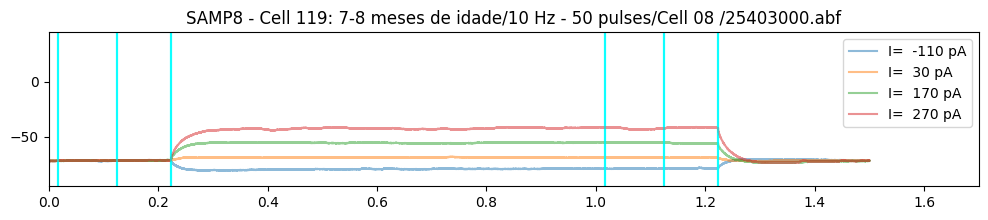

7-8 meses de idade/100 Hz - 50 pulses/Cell 01 /25324012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


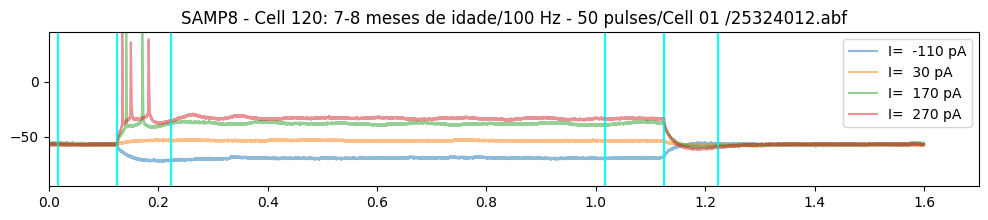

7-8 meses de idade/100 Hz - 50 pulses/Cell 02/25325010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/100 Hz - 50 pulses/Cell 03/25325020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


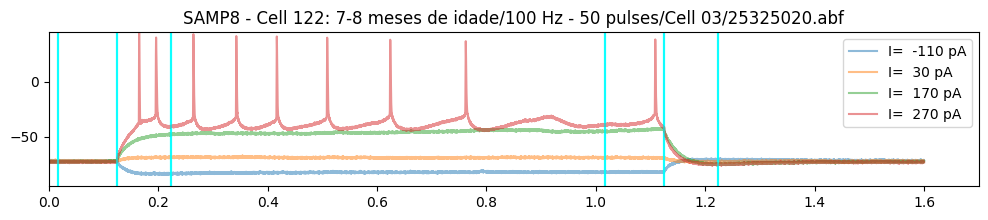

7-8 meses de idade/100 Hz - 50 pulses/Cell 04/25328000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


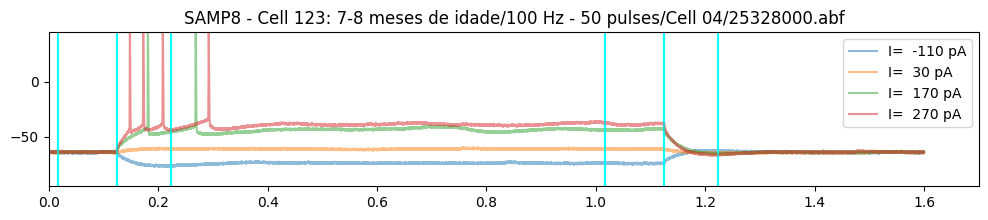

7-8 meses de idade/100 Hz - 50 pulses/Cell 05/25328010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


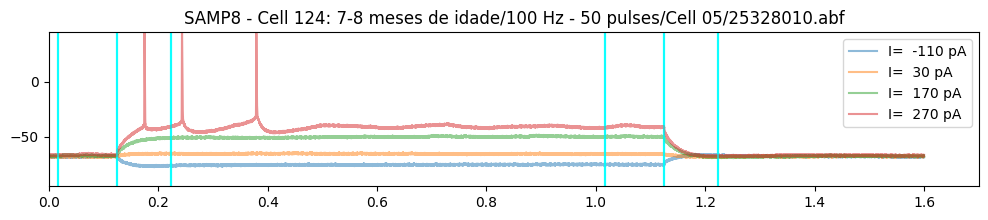

7-8 meses de idade/100 Hz - 50 pulses/Cell 06/25328018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


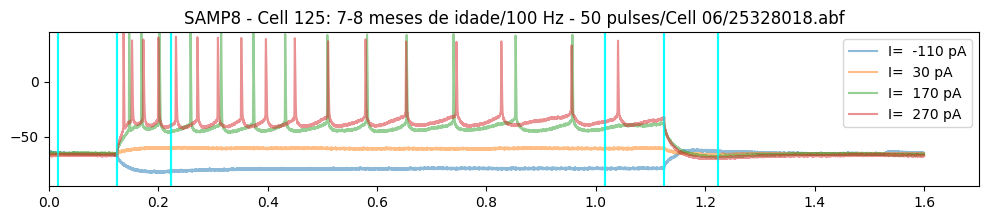

7-8 meses de idade/100 Hz - 50 pulses/Cell 07/25402004.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


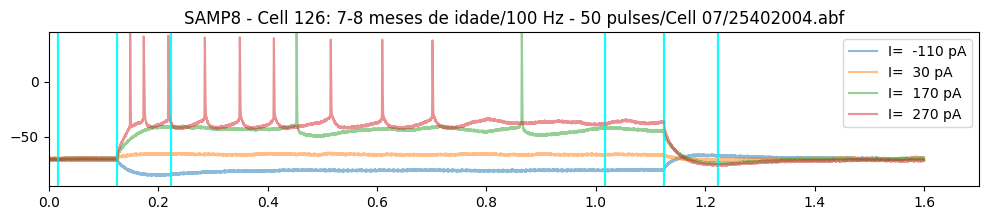

7-8 meses de idade/50 Hz/Controle/Cell 01/24322007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


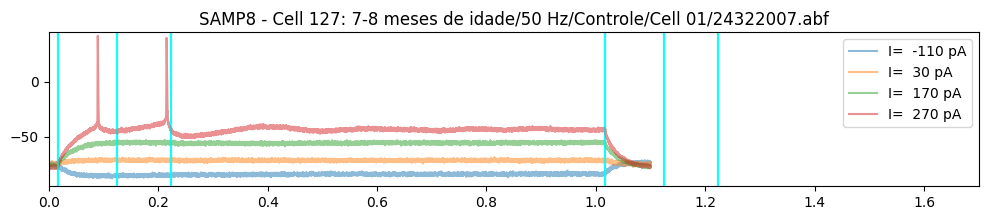

7-8 meses de idade/50 Hz/Controle/Cell 02/24322017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


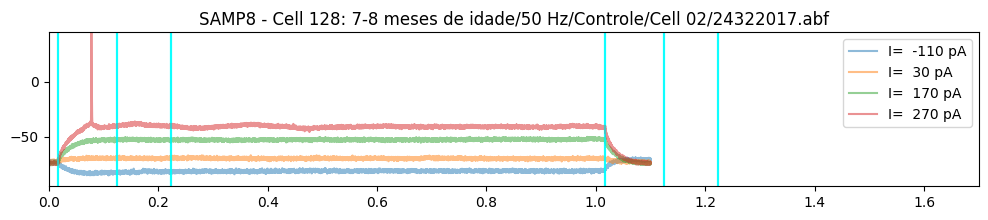

7-8 meses de idade/50 Hz/Controle/Cell 03/24325050.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


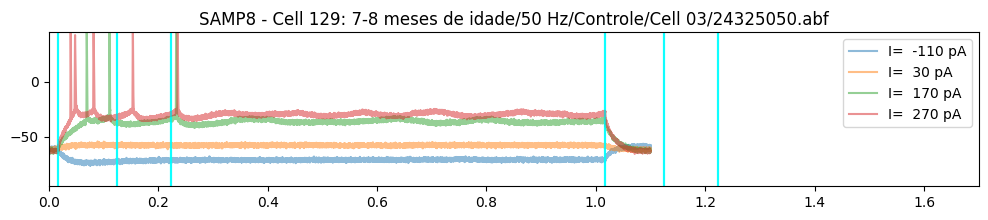

7-8 meses de idade/50 Hz/Controle/Cell 04/24325059.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


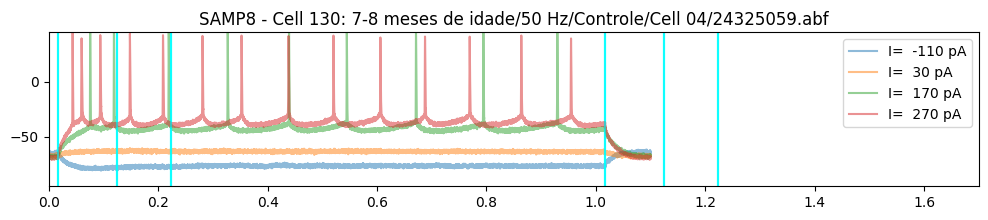

7-8 meses de idade/50 Hz/Controle/Cell 05/24516000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


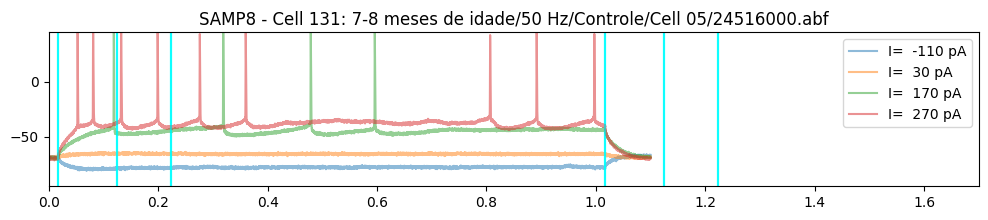

7-8 meses de idade/50 Hz/Controle/Cell 06/24516024.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


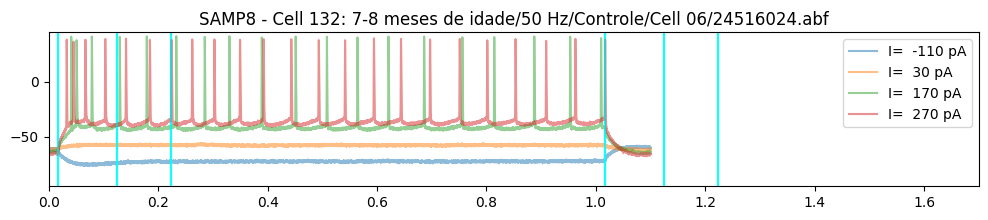

7-8 meses de idade/50 Hz/Controle/Cell 07/24404018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


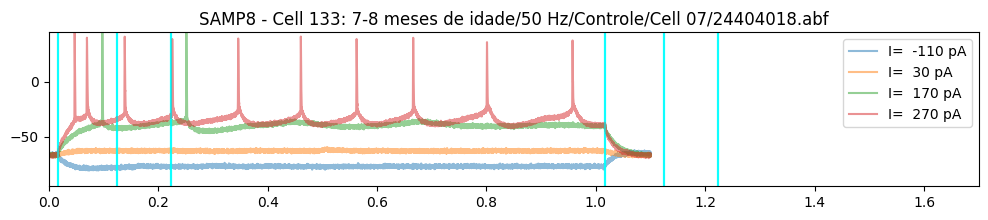

7-8 meses de idade/50 Hz/Controle/Cell 08 - Incomplete/24408020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


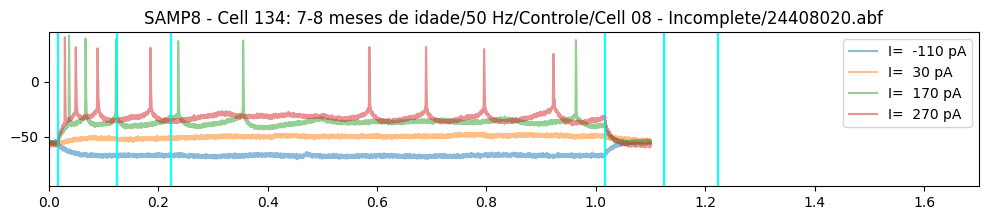

7-8 meses de idade/50 Hz/Controle/Cell 09 - Incomplete/24516008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


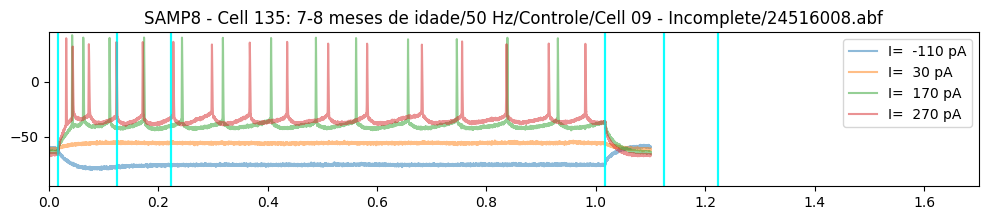

7-8 meses de idade/50 Hz/Controle/Cell 11 - Incomplete/24516019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


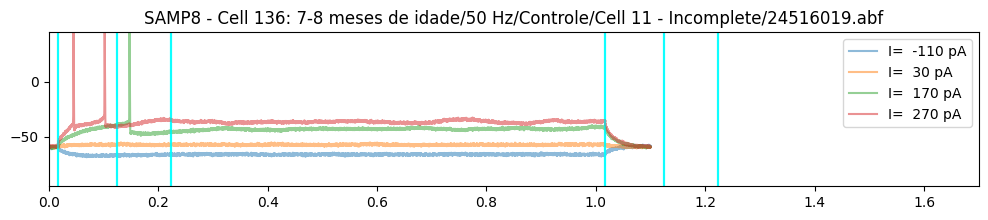

7-8 meses de idade/50 Hz/Controle/Cell 12 - incomplete/24520000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


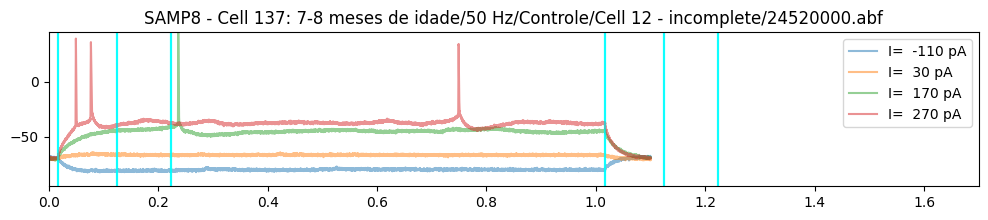

7-8 meses de idade/50 Hz/Controle/Cell 14/25313000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


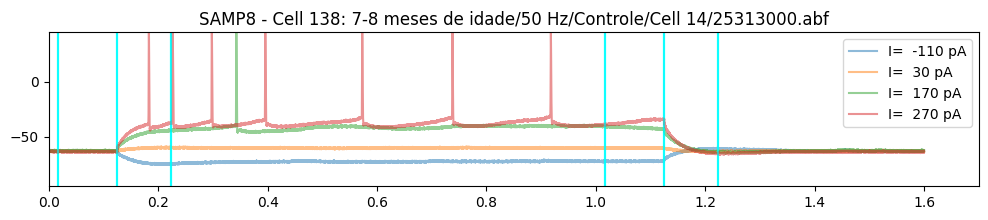

7-8 meses de idade/Cafeina/ZM - Antag. A2AR/Cell 01/24403022.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


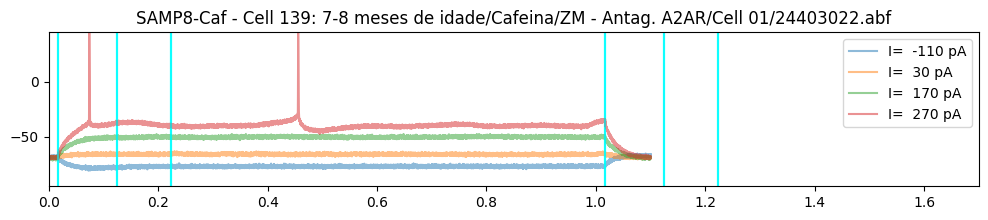

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 01/24525030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


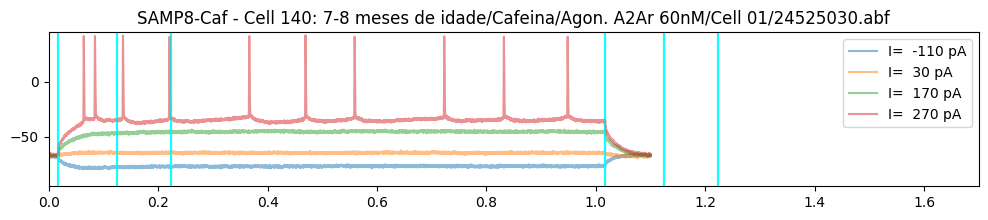

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 02/24606000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


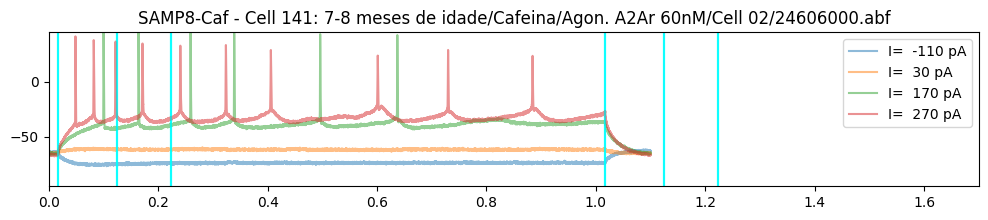

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 03/24607002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


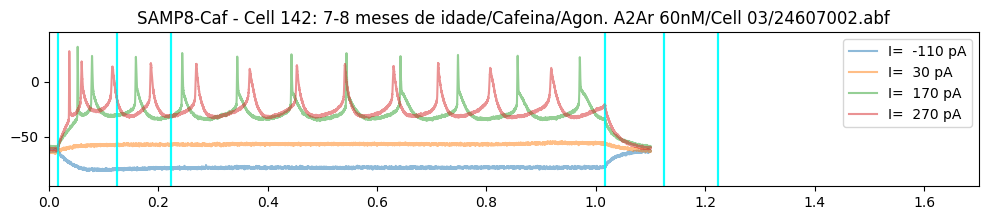

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 04/24607010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


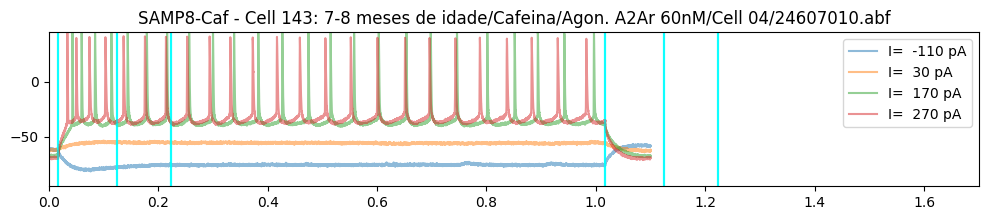

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 05/24608009.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


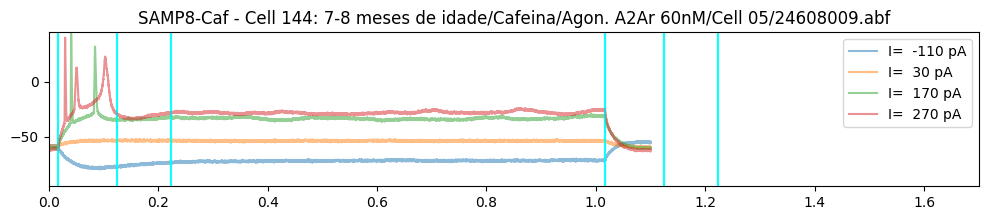

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 06/24o15020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


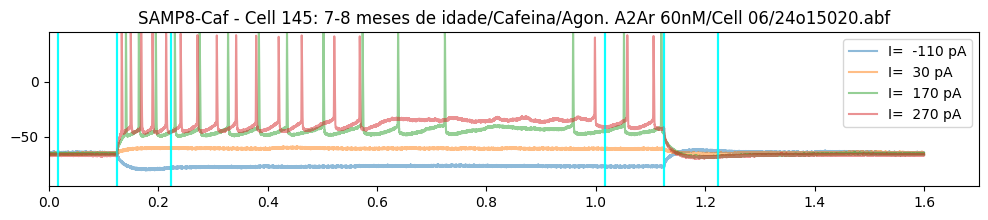

7-8 meses de idade/Cafeina/Agon. A2Ar 60nM/Cell 08/25207021.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


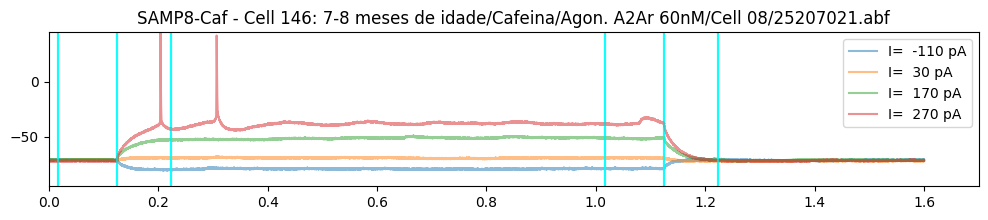

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 01/24327029.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


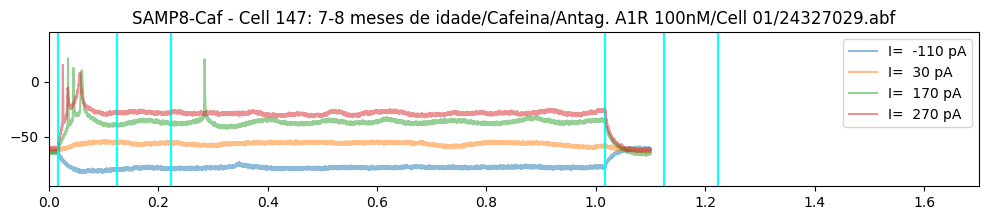

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 03/24328025.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 04/24329000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


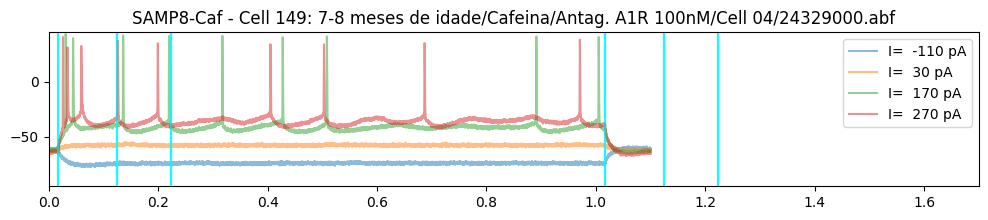

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 05/24329019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 06/24329027.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


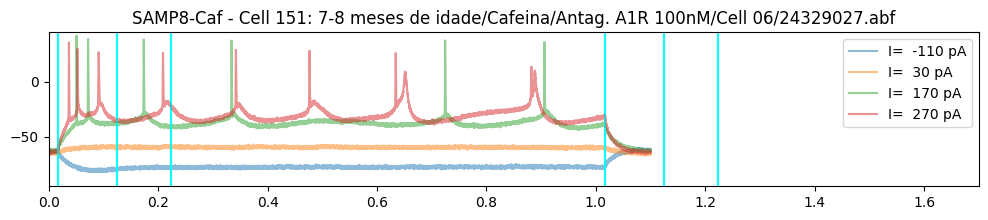

7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 07/24401010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Antag. A1R 100nM/Cell 08/24401018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 07/24210000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


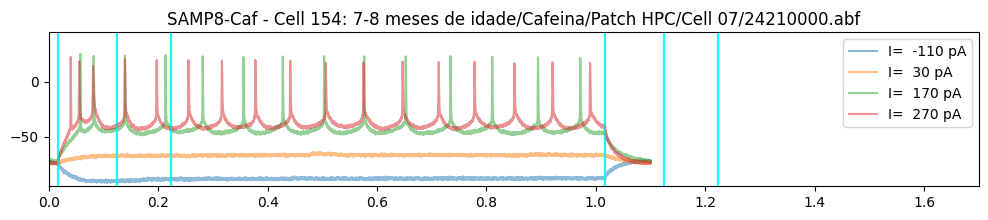

7-8 meses de idade/Cafeina/Patch HPC/Cell 08/24210020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


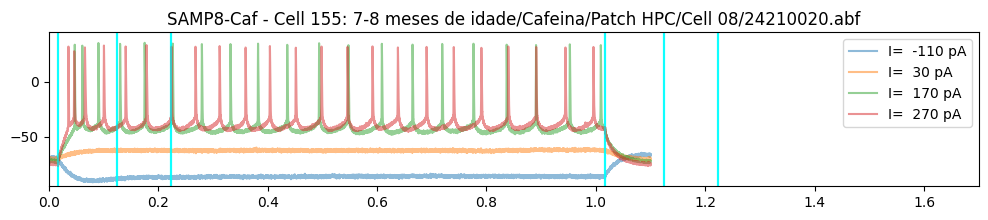

7-8 meses de idade/Cafeina/Patch HPC/Cell 09/24210053.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


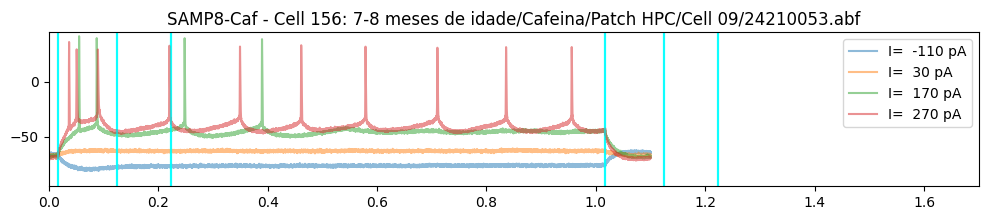

7-8 meses de idade/Cafeina/Patch HPC/Cell 10/24210069.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


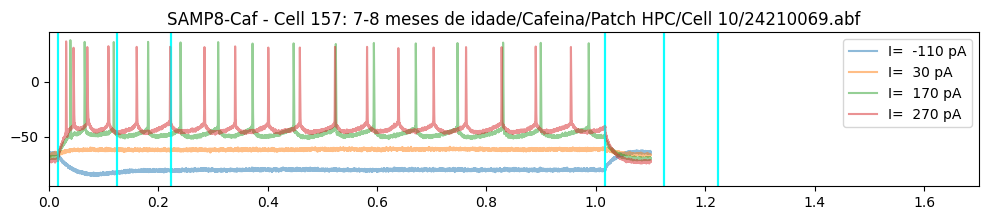

7-8 meses de idade/Cafeina/Patch HPC/Cell 11/24212039.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


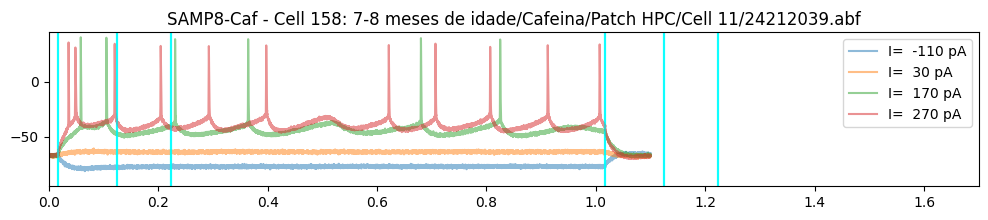

7-8 meses de idade/Cafeina/Patch HPC/Cell 12/24212055.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


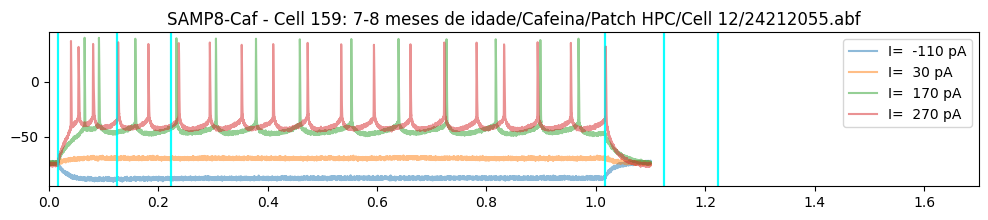

7-8 meses de idade/Cafeina/Patch HPC/Cell 13/24212071.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


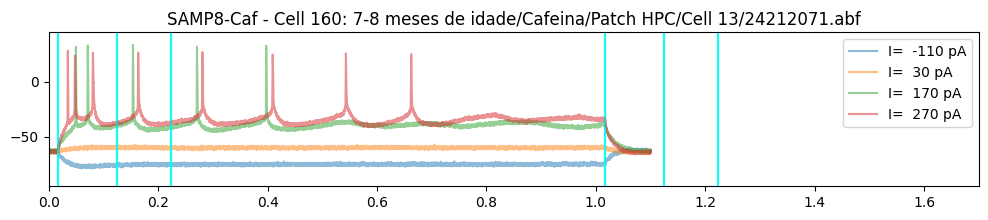

7-8 meses de idade/Cafeina/Patch HPC/Cell 14/24214059.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


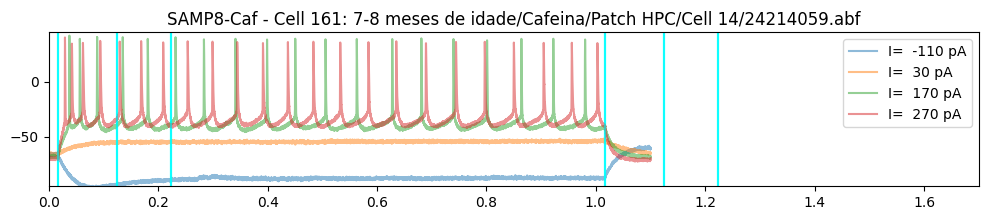

7-8 meses de idade/Cafeina/Patch HPC/Cell 15/24214079.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


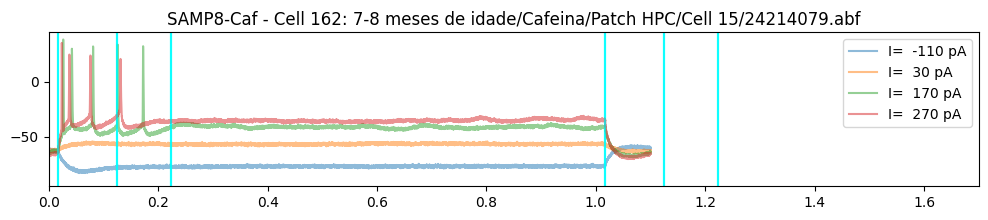

7-8 meses de idade/Cafeina/Patch HPC/Cell 16/24216001.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 17/24216017.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


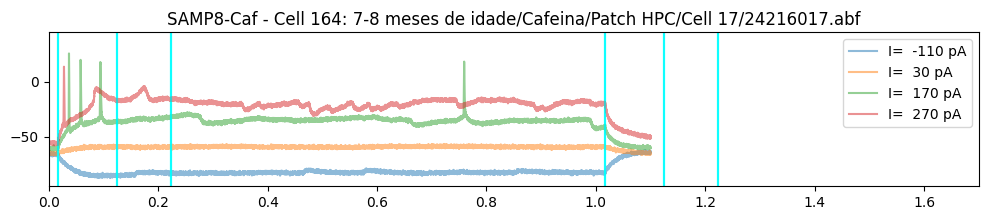

7-8 meses de idade/Cafeina/Patch HPC/Cell 18/24216020.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


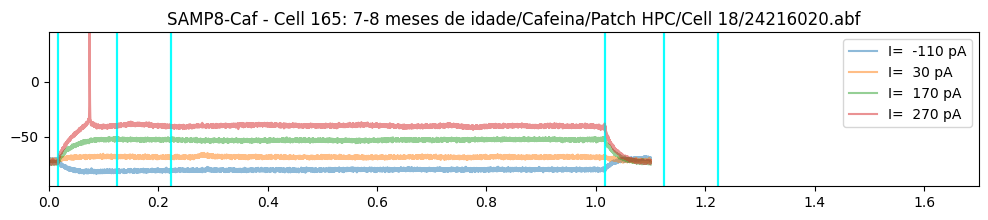

7-8 meses de idade/Cafeina/Patch HPC/Cell 19/24216072.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


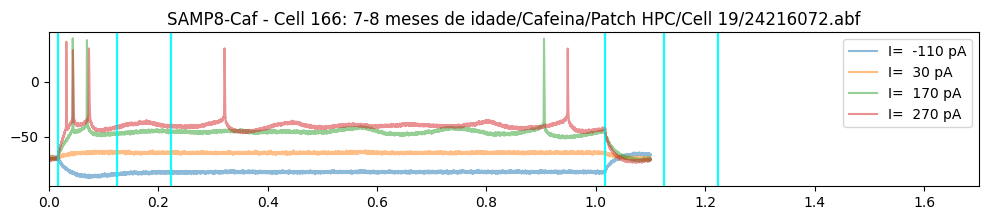

7-8 meses de idade/Cafeina/Patch HPC/Cell 20/24217072.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


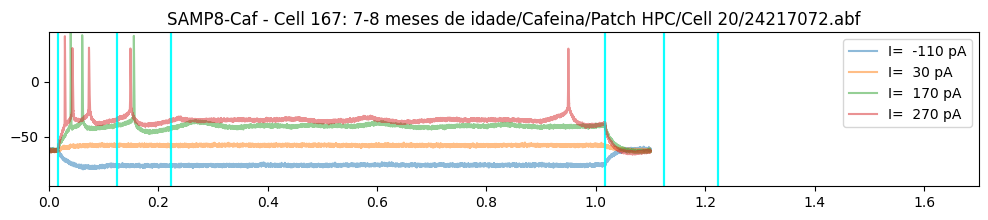

7-8 meses de idade/Cafeina/Patch HPC/Cell 21/24217084.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


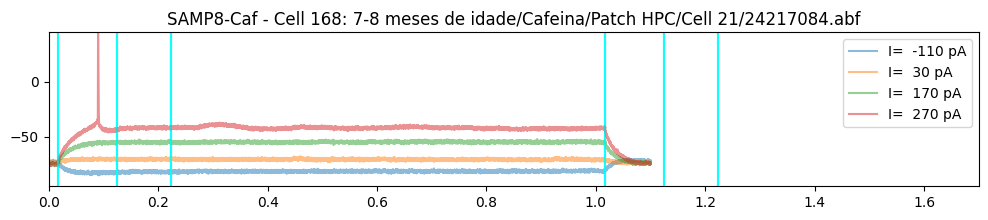

7-8 meses de idade/Cafeina/Patch HPC/Cell 22/24219000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


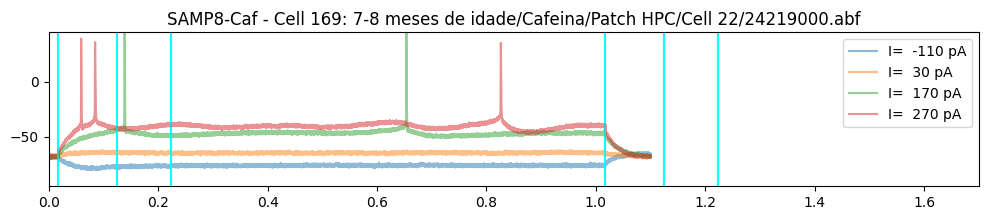

7-8 meses de idade/Cafeina/Patch HPC/Cell 23/24219016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


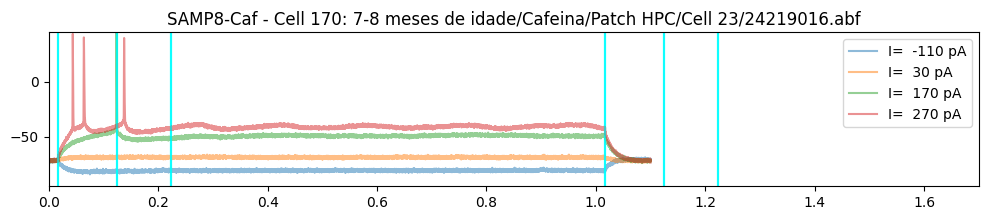

7-8 meses de idade/Cafeina/Patch HPC/Cell 24/24220000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


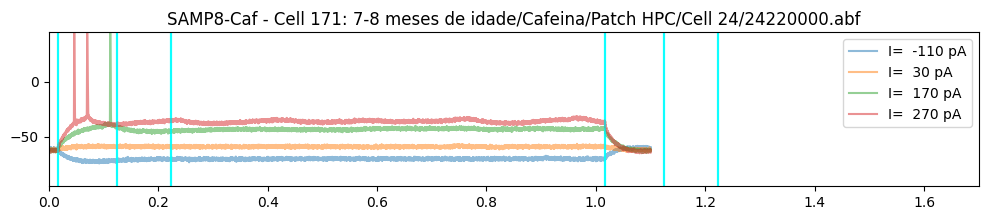

7-8 meses de idade/Cafeina/Patch HPC/Cell 25/24220016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Patch HPC/Cell 26/24220032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


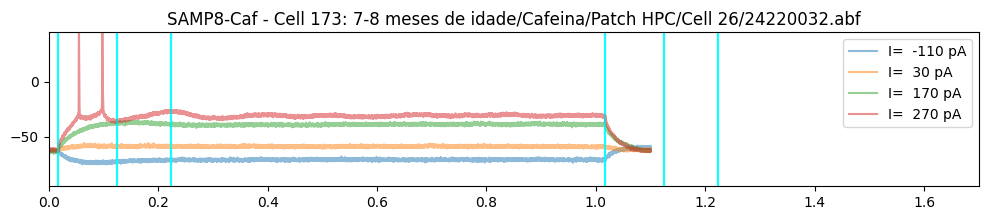

7-8 meses de idade/Cafeina/Patch HPC/Cell 27/24220099.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


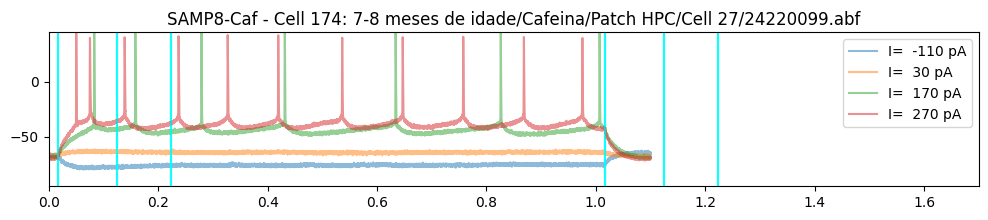

7-8 meses de idade/Cafeina/Patch HPC/Cell 28/24220115.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


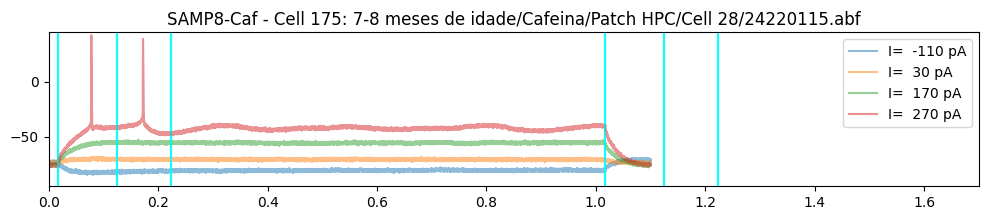

7-8 meses de idade/Cafeina/Patch HPC/Cell 29/24327008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


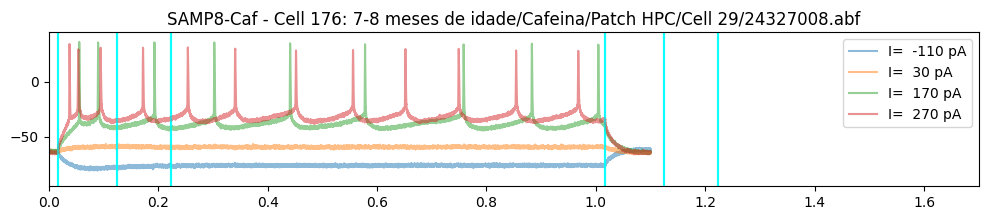

7-8 meses de idade/Cafeina/Patch HPC/Cell 30/24327018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


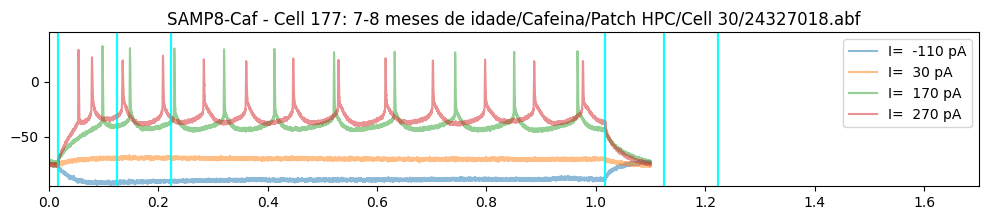

7-8 meses de idade/Cafeina/Patch HPC/Cell 32/24327036.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


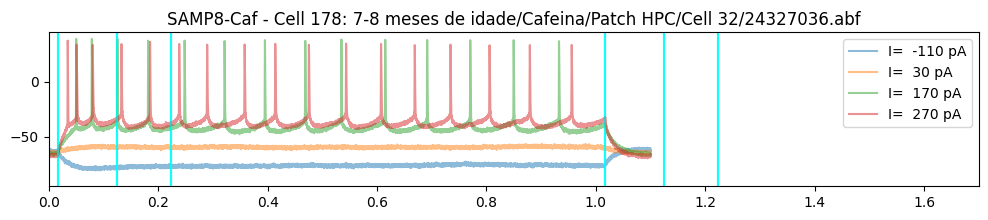

7-8 meses de idade/Cafeina/Patch HPC/Cell 33/24410008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/Cafeina/Patch HPC/Cell 34/24410012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
7-8 meses de idade/Cafeina/Patch HPC/Cell 35/24525010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


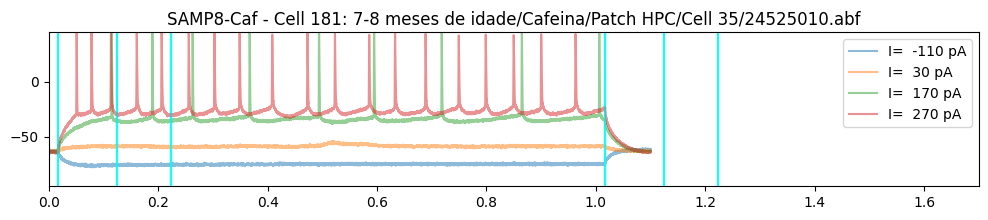

7-8 meses de idade/Cafeina/Patch HPC/Cell 36/24530000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


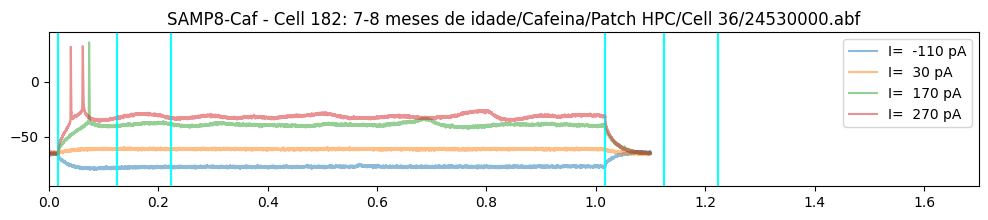

7-8 meses de idade/Cafeina/Patch HPC/Cell 37/24530002.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


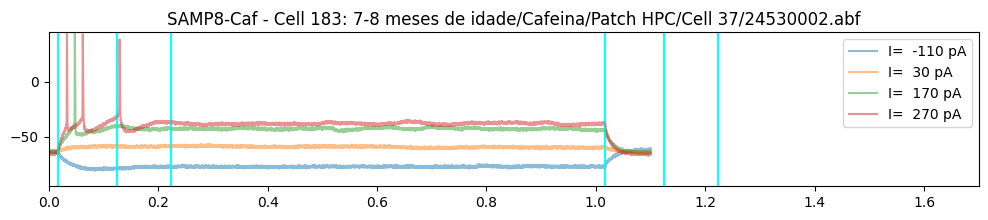

7-8 meses de idade/Cafeina/Patch HPC/Cell 38/24530008.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


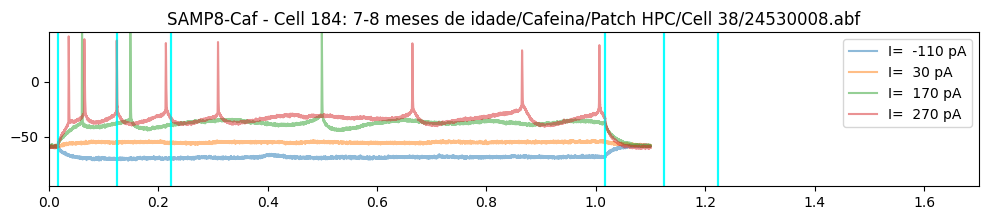

7-8 meses de idade/Cafeina/Patch HPC/Cell 39/24530013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


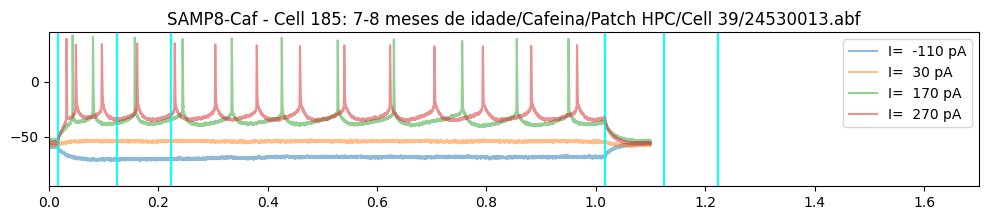

7-8 meses de idade/Cafeina/Patch HPC/Cell 40/24603000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


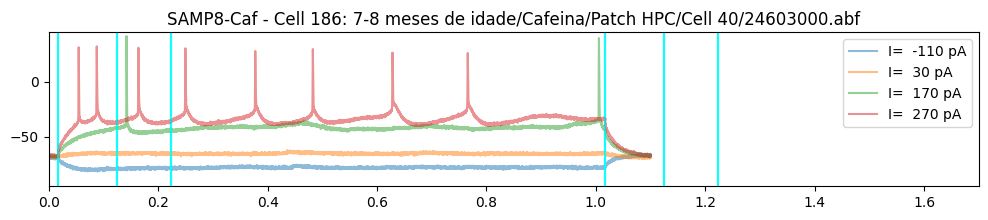

7-8 meses de idade/Cafeina/Patch HPC/Cell 41/24604000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


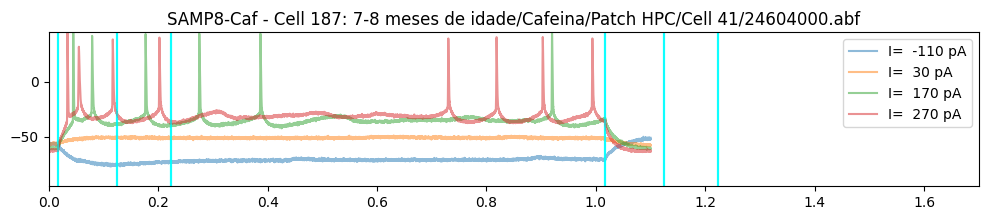

7-8 meses de idade/Cafeina/Patch HPC/Cell 42/24604013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


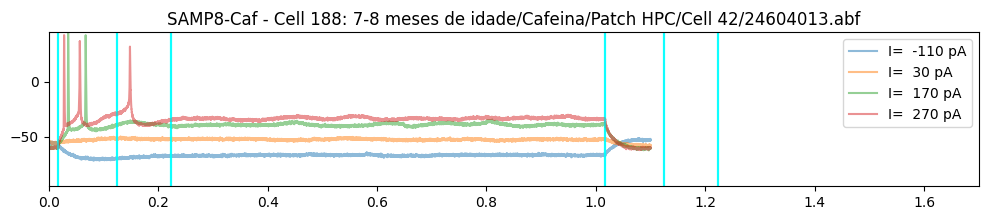

7-8 meses de idade/Cafeina/Patch HPC/Cell 43/24604018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


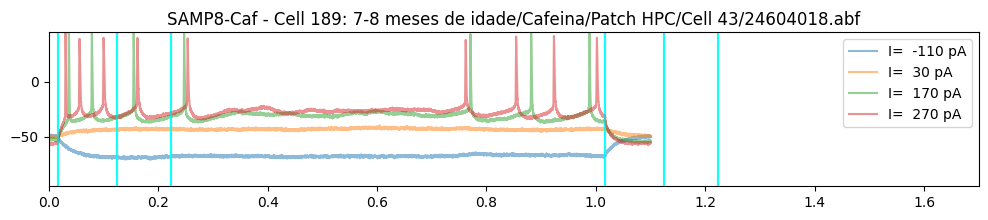

7-8 meses de idade/Cafeina/Patch HPC/Cell 44/24605000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
7-8 meses de idade/Cafeina/Patch HPC/Cell 46/24605010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


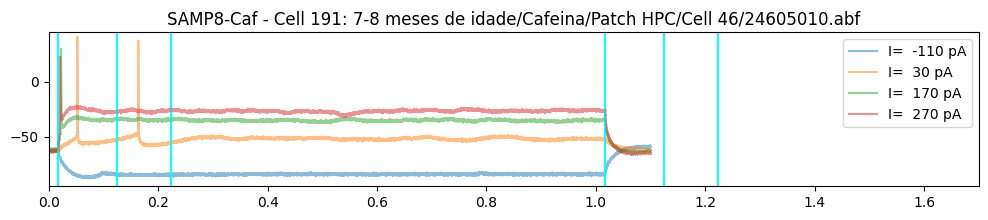

7-8 meses de idade/Cafeina/Patch HPC/Cell 47/24608000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


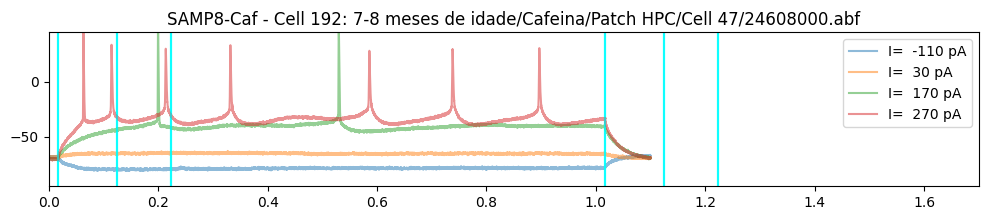

7-8 meses de idade/Cafeina/Patch HPC/Cell 48/24608003.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


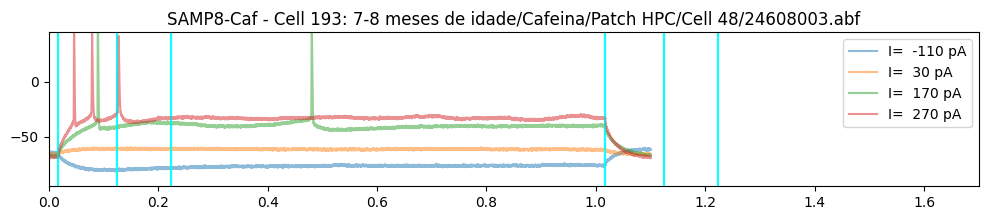

7-8 meses de idade/Cafeina/Patch HPC/Cell 49/25617018.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


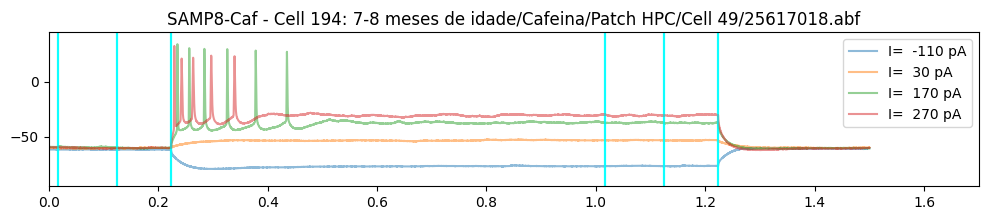

7-8 meses de idade/Cafeina/Patch HPC/Cell 50/25620003.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


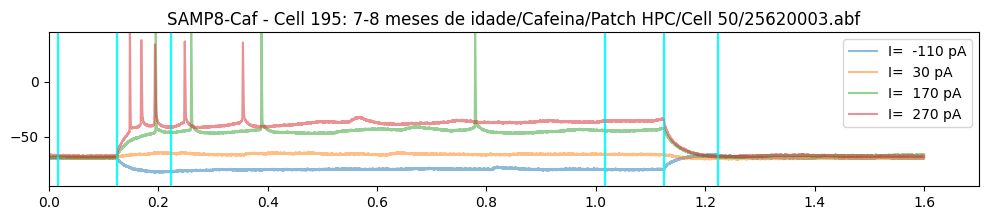

7-8 meses de idade/Cafeina/Patch HPC/Cell 51/25620019.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


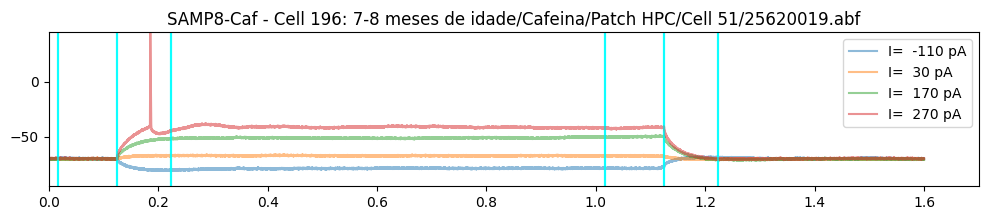

7-8 meses de idade/Cafeina/Patch HPC/Cell 52/25620035.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


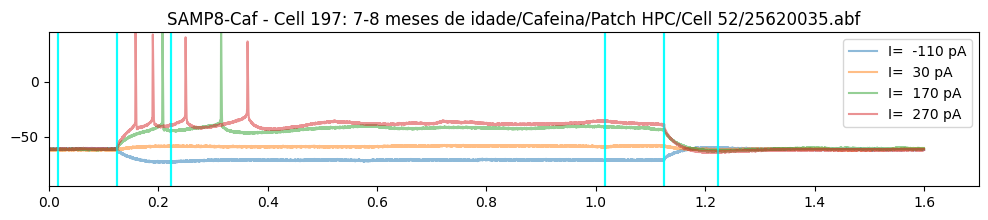

7-8 meses de idade/Cafeina/Patch HPC/Cell 53/25620051.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


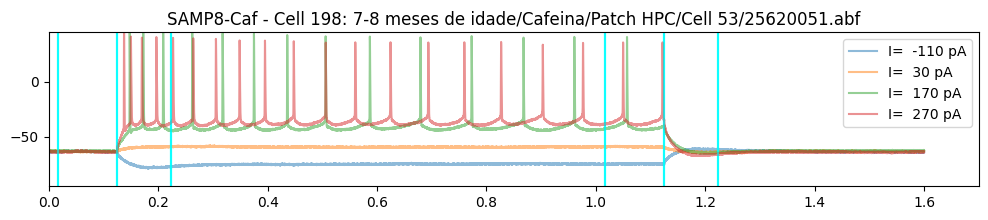

7-8 meses de idade/Cafeina/Patch HPC/Cell 54/25620000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/Patch HPC/Cell 55/25620016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


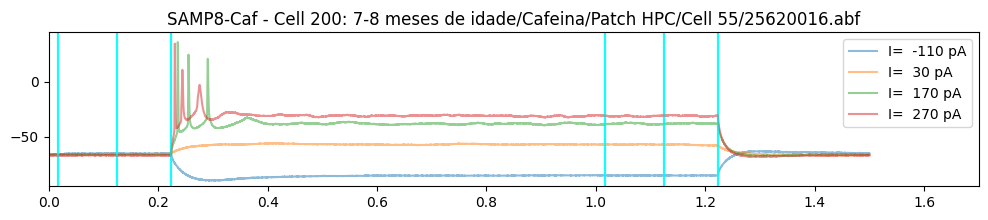

7-8 meses de idade/Cafeina/Patch HPC/Cell 56/26309000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
7-8 meses de idade/Cafeina/10 Hz/Cell 02/25130014.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


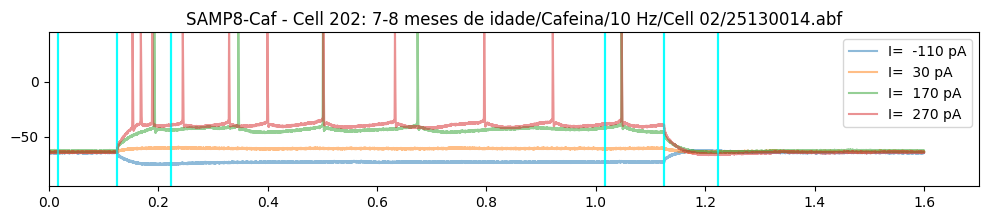

7-8 meses de idade/Cafeina/10 Hz/Cell 03/25131013.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


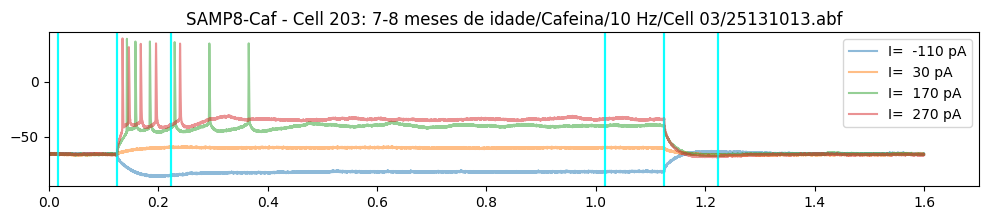

7-8 meses de idade/Cafeina/10 Hz/Cell 04/25203000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


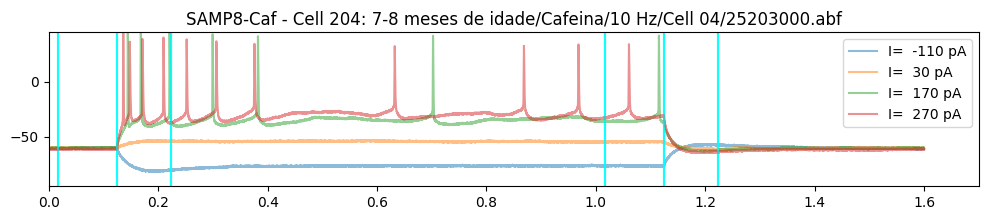

7-8 meses de idade/Cafeina/10 Hz/Cell 05/25206016.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


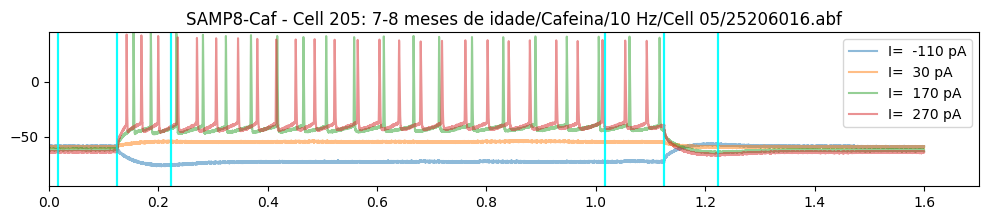

7-8 meses de idade/Cafeina/10 Hz/Cell 06/25207011.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


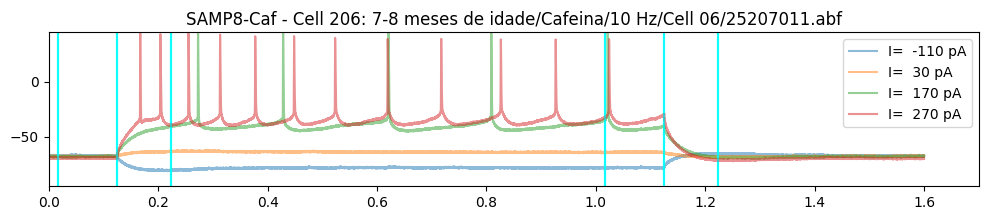

7-8 meses de idade/Cafeina/10 Hz/Cell 07 /25213022.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


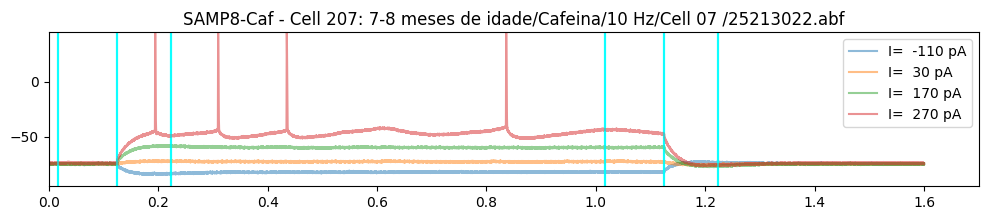

7-8 meses de idade/Cafeina/10 Hz/Cell 08 ** /25213012.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


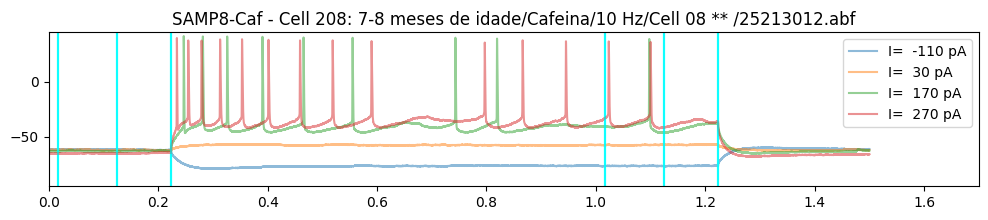

7-8 meses de idade/Cafeina/100 Hz/Cell 01/25130000.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


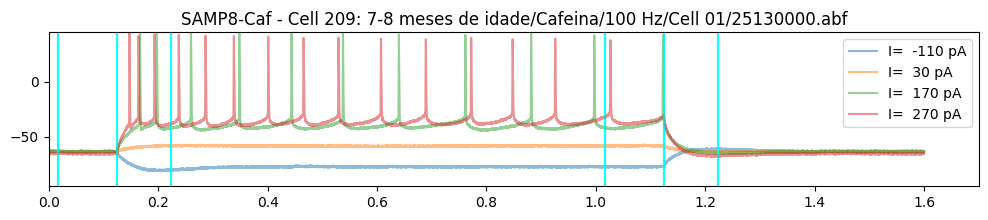

7-8 meses de idade/Cafeina/100 Hz/Cell 02/25131042.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


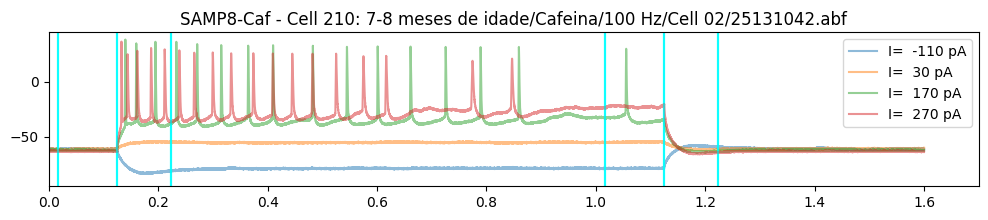

7-8 meses de idade/Cafeina/100 Hz/Cell 03/25203010.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


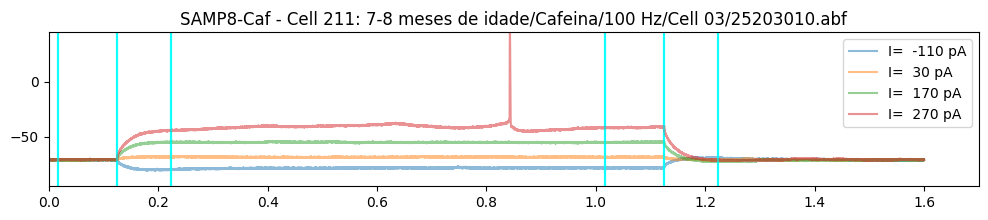

7-8 meses de idade/Cafeina/100 Hz/Cell 04/25206007.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


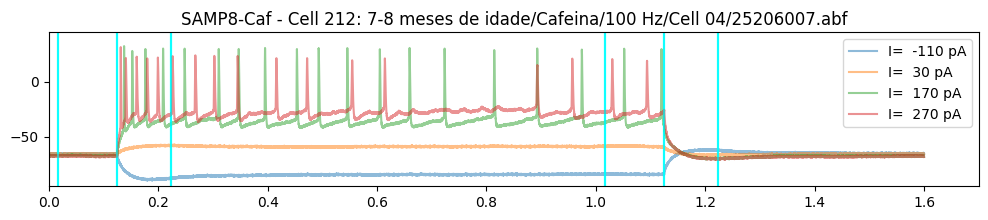

7-8 meses de idade/Cafeina/100 Hz/Cell 05/25207030.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


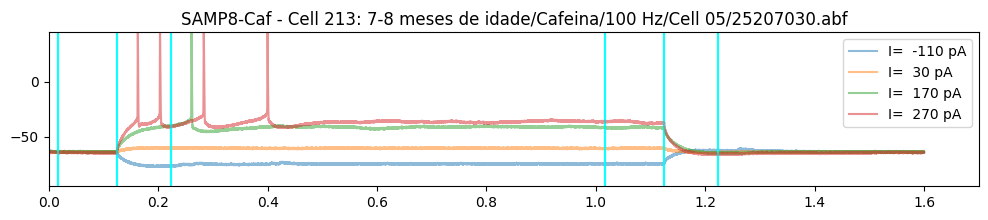

7-8 meses de idade/Cafeina/100 Hz/Cell 07/25213032.abf Long current step for pyramidal neurons_Allen [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


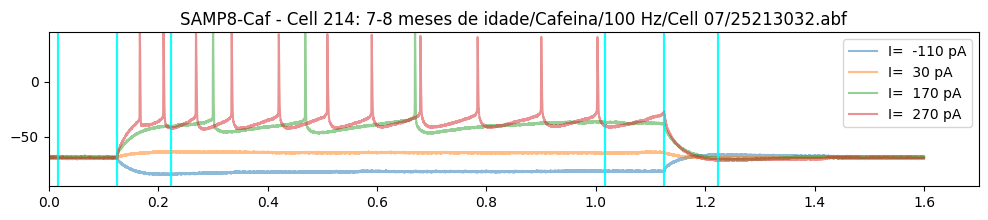

In [ ]:
############################################
# Pesquisando Celulas disponiveis
# Criar Lists com dados de Todas Células
# Salva um excel file no mesma pasta da célula
############################################

# Definir os folders para analises

fldrs = ['7-8 meses de idade/','7-8 meses de idade/Cafeina/','50-70 dias de idade SAMP-8 controle/']

# Definir nome do protocolo de interesse
protocolo = "Long"

times = []
voltages = []
I = []
cellnames = []
groupnames = []
subgroup = []
abfnames = []

Interneurons = [] # no spike in Control25
ListaPaTCH = []

cellnumber = 0
for filename in ListaFiles:

                firstREO = 0

                abf = pyabf.ABF(filename)
                fs = abf.dataRate

                if protocolo in abf.protocol and len(abf.sweepList) >= 19:

                    ############################################
                    # Save Data and plot
                    ############################################

                    print(filename, abf.protocol, abf.sweepList)
                    # print(abf)

                    cellnumber = cellnumber + 1
                    celname = 'Cell ' + str(cellnumber)


                    outlier = 1
                    for i in abf.sweepList: # GUI>> modf p dados do gui (muitos steps)

                        abf.setSweep(i, channel=0)
                        peaks, peaksV = find_peaks(abf.sweepY, height=0, distance=200) # V > 0 mV and ISI > 10 ms (at 20kHz)
                        peak_count = len(peaks)
                        if peak_count >= 3:
                          outlier = 0

                    for i in abf.sweepList[0:20]: # GUI>> modf p dados do gui (muitos steps)
                        abf.setSweep(i, channel=0)
                        peaks, peaksV = find_peaks(abf.sweepY, height=0, distance=200) # V > 0 mV and ISI > 10 ms (at 20kHz)
                        peak_count = len(peaks)
                        if peak_count > 30:
                          outlier = 1

                    if "7-8 meses de idade/HPC whole cell/SAMP-8/Cell 37/24618002.abf" == filename:
                        outlier = 1

                    if outlier == 0:
                      IpA = -110
                      plt.figure(figsize=(12, 2))
                      for i in abf.sweepList: # GUI>> modf p dados do gui (muitos steps)
                          abf.setSweep(i, channel=0)
                          I.append((-110+20*i + abf.sweepC))
                          IpA = IpA + 20.0
                          times.append(abf.sweepX)
                          voltages.append(abf.sweepY)

                          abfname = filename.split('/')[-2] + '/' + filename.split('/')[-1]
                          abfnames.append(abfname)

                          cellnames.append(celname + '/' + filename.split('/')[-1])


                          if '50-70 dias de idade SAMP-8 controle/' in filename:
                            gname = 'SAMP2'
                          elif '7-8 meses de idade/Cafeina/' in filename:
                            gname = 'SAMP8-Caf'
                          else:
                            gname = 'SAMP8'

                          groupnames.append(gname)

                          if i == 0 or i == 7 or i == 14 or i == 19:
                            plt.plot(abf.sweepX, abf.sweepY, alpha=.5,
                                      label="I=  %.0f pA" % (IpA-20.0))
                            # b, a = signal.butter(4, 0.05, "low")
                            # current_filtered = signal.filtfilt(b, a, abf.sweepY, padlen=150)
                            # plt.plot(abf.sweepX, current_filtered, alpha=.5, color='r', linewidth=2.5,
                            #           label="I=  %.0f pA" % (IpA-20.0))
                            plt.legend()
                            plt.title(gname + " - " + celname + ": "+(filename))
                            # plt.ylim(min(abf.sweepY[50:150])-5.0,min(abf.sweepY[50:150])+95)
                            plt.xlim(0.0,1.7)
                            plt.ylim(-95.0,45)
                            plt.vlines(x=[0.0172, 0.125, 0.2234, 1.0172, 1.125, 1.2234], ymin=-95.0, ymax=45.0, color='cyan', alpha = 0.5)

                      plt.show()


# Analises

In [ ]:
allcells, allcont = np.unique(cellnames,return_counts = True)

In [ ]:
allgroups, allcont = np.unique(groupnames,return_counts = True)

allgroups[0], allcont[0]/1, allgroups[1], allcont[1]/1, allgroups[2], allcont[2]/1

(np.str_('SAMP2'),
 np.float64(1187.0),
 np.str_('SAMP8'),
 np.float64(1415.0),
 np.str_('SAMP8-Caf'),
 np.float64(1382.0))

In [ ]:
# all
# NCells_SAMP2 = 49
# NCells_SAMP8 = 68
# NCells_SAMP8_Caf = 64

# # excluindo outliers
# NCells_SAMP2 = 40
# NCells_SAMP8 = 66
# NCells_SAMP8_Caf = 59

# excluindo outliers and include 4 more Samp2
NCells_SAMP2 = 44
NCells_SAMP8 = 66
NCells_SAMP8_Caf = 59

In [ ]:
allabfs, allcontabf = np.unique(abfnames,return_counts = True)
allabfs[allcontabf > 26], allcontabf[allcontabf > 26]

(array(['Cell 08 /25403000.abf', 'Cell 09/25417030.abf',
        'Cell 10 - 100nM/24319014.abf'], dtype='<U33'),
 array([30, 29, 30]))

In [ ]:
############################################
# Analise eFEL (do Blue Brain Project)
############################################
traces = []

# for ii in range(0, len(voltages)):  # MUDEI, era anf.sweepList
for ii in range(0, len(voltages)):  # MUDEI, era anf.sweepList


    if len(voltages[ii])/20000 < 1.2:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [17.2], 'stim_end': [1017.2]} #0.0172, 0.125, 0.2234
      traces.append(trace)
    elif len(voltages[ii])/20000 < 1.55:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [223.4], 'stim_end': [1223.4]} #0.0172, 0.125, 0.2234
      traces.append(trace)
    else:
      trace = {'T': 1000.0*times[ii], 'V': voltages[ii],
              'I': I[ii],
              'stim_start': [125.0], 'stim_end': [1125.0]} #0.0172, 0.125, 0.2234
      traces.append(trace)

Lista_de_medidas = ['voltage_base', 'steady_state_voltage_stimend', 'voltage_deflection', 'time_to_first_spike', 'time_to_second_spike',  'time_to_last_spike', 'Spikecount', 'mean_frequency',
                    'decay_time_constant_after_stim',
                    'sag_amplitude', 'sag_time_constant', 'minimum_voltage',
                    'sag_ratio1']

# Optional: You can adjust the parameters for the calculation of the time constant
efel.set_setting("Threshold", 0.0)
# efel.setDoubleSetting('decay_start_after_stim', 0)  # default = 1 ms
# efel.setDoubleSetting('decay_end_after_stim', 30)  # default = 10 ms

feature_values = efel.get_feature_values(traces, Lista_de_medidas, raise_warnings=False);

In [ ]:
feature_values[-1]

{'voltage_base': array([-69.4771]),
 'steady_state_voltage_stimend': array([-36.0953]),
 'voltage_deflection': array([41.7783]),
 'time_to_first_spike': array([41.3]),
 'time_to_second_spike': array([84.6]),
 'time_to_last_spike': array([877.8]),
 'Spikecount': array([11]),
 'mean_frequency': array([12.5313]),
 'decay_time_constant_after_stim': array([16.0144]),
 'sag_amplitude': None,
 'sag_time_constant': None,
 'minimum_voltage': array([-67.1692]),
 'sag_ratio1': None}

## Salvar planilhas

In [ ]:
# Set the columns of the output table
table = pd.DataFrame(columns=['cell',
                              'path',
                              'abf',
                              'current_pA',
                              'group',
                              'voltage_base',
                              'steady_state_voltage_stimend',
                              'voltage_delta',
                              'voltage_deflection',
                              'time_constant',
                              'decay_time_constant_after_stim',
                              'capacitance_pF',
                              'sag_amplitude',
                              'sag_ratio1',
                              'Spikecount',
                              'mean_frequency', 'time_to_first_spike', 'time_to_second_spike',  'time_to_last_spike',
                              'reobase'])

In [ ]:
reobaseList = []
jj = -1
for ii in range(0, len(voltages)):

    if I[ii][0] < -105.0:
      jj = jj + 1
      firstSpike = 0

    if feature_values[ii]['Spikecount'] > 0:
      if firstSpike == 0:
        firstSpike = 1
        reobaseList.append(I[ii][0])


In [ ]:
jj = -1
for ii in range(0, len(voltages)):

    if I[ii][0] < -105.0:
      jj = jj + 1

    length = len(table)

    table.loc[ii, 'cell'] = cellnames[ii]
    table.loc[ii, 'path'] = ListaFiles[jj]
    table.loc[ii, 'abf'] = abfnames[jj]

    table.loc[ii, 'current_pA'] = I[ii][0]
    table.loc[ii, 'group'] =  groupnames[ii]
    table.loc[ii, 'voltage_base'] = feature_values[ii]['voltage_base'][0]
    table.loc[ii, 'steady_state_voltage_stimend'] = feature_values[ii]['steady_state_voltage_stimend'][0]
    table.loc[ii, 'voltage_delta'] = (feature_values[ii]['steady_state_voltage_stimend'][0] - feature_values[ii]['voltage_base'][0])
    table.loc[ii, 'voltage_deflection'] = feature_values[ii]['voltage_deflection'][0]
    table.loc[ii, 'decay_time_constant_after_stim'] = feature_values[ii]['decay_time_constant_after_stim'][0]

    table.loc[ii, 'reobase'] = reobaseList[jj]
    if feature_values[ii]['Spikecount'][0] > 0:
      table.loc[ii, 'mean_frequency'] = float(feature_values[ii]['mean_frequency'][0])
      table.loc[ii, 'Spikecount'] = float(feature_values[ii]['Spikecount'][0])
      table.loc[ii, 'time_to_first_spike'] = float(feature_values[ii]['time_to_first_spike'][0])
      table.loc[ii, 'time_to_last_spike'] = float(feature_values[ii]['time_to_last_spike'][0])
      if feature_values[ii]['Spikecount'][0] > 1:
        table.loc[ii, 'time_to_second_spike'] = float(feature_values[ii]['time_to_second_spike'][0])
      else:
        table.loc[ii, 'time_to_second_spike'] = 0.0
    else:
      table.loc[ii, 'mean_frequency'] = 0.0
      table.loc[ii, 'Spikecount'] = 0.0
      table.loc[ii, 'time_to_first_spike'] = 0.0
      table.loc[ii, 'time_to_last_spike'] = 0.0
      table.loc[ii, 'time_to_second_spike'] = 0.0

    if I[ii][0] < -30.0:
        table.loc[ii, 'sag_amplitude'] = feature_values[ii]['sag_amplitude'][0]
        table.loc[ii, 'sag_ratio1'] = feature_values[ii]['sag_ratio1'][0]
        table.loc[ii, 'input_resistance_Gohm'] = (table.loc[ii, 'voltage_delta']
                                                      /table.loc[ii, 'current_pA'])

        if (feature_values[ii]['decay_time_constant_after_stim'] is not None):
            table.loc[ii, 'time_constant'] = feature_values[ii]['decay_time_constant_after_stim'][0]
            table.loc[ii, 'capacitance_pF'] = (feature_values[ii]['decay_time_constant_after_stim']
                                                   /table.loc[ii, 'input_resistance_Gohm'])[0]

In [ ]:
table['path'].unique()

array(['50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 01 - Incomplete/24523000.abf',
       '50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 02/24523015.abf',
       '50-70 dias de idade SAMP-8 controle/HPC - CPT-8/Cell 03/24523018.abf',
       ..., '7-8 meses de idade/Cafeina/Patch HPC/Cell 21/24217084.abf',
       '7-8 meses de idade/Cafeina/Patch HPC/Cell 22/24219000.abf',
       '7-8 meses de idade/Cafeina/Patch HPC/Cell 23/24219016.abf'],
      dtype=object)

In [ ]:
table['abf'].unique()

array(['Cell 01 - Incomplete/24523000.abf', 'Cell 02/24523015.abf',
       'Cell 03/24523018.abf', ..., 'Cell 09/25417030.abf',
       'Cell 10 /25418000.abf', 'Cell 10/23516014.abf'], dtype=object)

In [ ]:
table["group"].unique()

array(['SAMP2', 'SAMP8', 'SAMP8-Caf'], dtype=object)

In [ ]:
SAMP8 = table.get(table["group"] == "SAMP8")
SAMP8_Caf = table.get(table["group"] == "SAMP8-Caf")
SAMP2 = table.get(table["group"] == "SAMP2")
SAMP8

,cell,path,abf,current_pA,group,voltage_base,steady_state_voltage_stimend,voltage_delta,voltage_deflection,time_constant,...,capacitance_pF,sag_amplitude,sag_ratio1,Spikecount,mean_frequency,time_to_first_spike,time_to_second_spike,time_to_last_spike,reobase,input_resistance_Gohm
1187,Cell 59/24311000.abf,50-70 dias de idade SAMP-8 controle/10 Hz/Cell...,Cell 03/24523018.abf,-110.0,SAMP8,-78.116523,-88.131073,-10.01455,-9.756382,7.090088,...,77.877657,3.757355,0.272828,0.0,0.0,0.0,0.0,0.0,170.0,0.091041
1188,Cell 59/24311000.abf,50-70 dias de idade SAMP-8 controle/10 Hz/Cell...,Cell 03/24523018.abf,-90.0,SAMP8,-77.204386,-86.487457,-9.283071,-9.290221,11.36612,...,110.1953,3.295258,0.261979,0.0,0.0,0.0,0.0,0.0,170.0,0.103145
1189,Cell 59/24311000.abf,50-70 dias de idade SAMP-8 controle/10 Hz/Cell...,Cell 03/24523018.abf,-70.0,SAMP8,-77.301025,-84.556335,-7.25531,-7.684996,14.81131,...,142.901087,2.998596,0.292435,0.0,0.0,0.0,0.0,0.0,170.0,0.103647
1190,Cell 59/24311000.abf,50-70 dias de idade SAMP-8 controle/10 Hz/Cell...,Cell 03/24523018.abf,-50.0,SAMP8,-77.616374,-82.856262,-5.239889,-5.101022,11.853823,...,113.111407,2.592957,0.331036,0.0,0.0,0.0,0.0,0.0,170.0,0.104798
1191,Cell 59/24311000.abf,50-70 dias de idade SAMP-8 controle/10 Hz/Cell...,Cell 03/24523018.abf,-30.0,SAMP8,-77.426487,-80.977112,-3.550625,-3.021029,NaN,...,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,170.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2597,Cell 138/25313000.abf,7-8 meses de idade/HPC whole cell/SAMP-8/Cell ...,Cell 08/25415031.abf,190.0,SAMP8,-62.926514,-39.403351,23.523163,21.173164,NaN,...,NaN,NaN,NaN,4.0,4.02617,125.5,259.1,993.5,150.0,NaN
2598,Cell 138/25313000.abf,7-8 meses de idade/HPC whole cell/SAMP-8/Cell ...,Cell 08/25415031.abf,210.0,SAMP8,-62.795654,-41.861359,20.934296,23.330423,NaN,...,NaN,NaN,NaN,3.0,3.436426,113.4,233.1,873.0,150.0,NaN
2599,Cell 138/25313000.abf,7-8 meses de idade/HPC whole cell/SAMP-8/Cell ...,Cell 08/25415031.abf,230.0,SAMP8,-63.017334,-37.806793,25.210541,24.428392,NaN,...,NaN,NaN,NaN,5.0,6.788866,74.5,150.7,736.5,150.0,NaN
2600,Cell 138/25313000.abf,7-8 meses de idade/HPC whole cell/SAMP-8/Cell ...,Cell 08/25415031.abf,250.0,SAMP8,-63.63501,-36.029816,27.605194,22.320259,NaN,...,NaN,NaN,NaN,6.0,6.199628,66.6,125.3,967.8,150.0,NaN


In [ ]:
# ---------------------------------------  #
output_filename = 'Resultados_PAs_2026/SAMP8_Electrophysiology_Data_onePercell.xlsx'

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP8_pivot = SAMP8.pivot_table(index='current_pA', columns='cell', values='steady_state_voltage_stimend')

# Save the pivoted DataFrame to an Excel file
SAMP8_pivot.to_excel(output_filename, sheet_name='steady_state_voltage_stimend', float_format="%.2f")

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP8_pivot = SAMP8.pivot_table(index='current_pA', columns='cell', values='Spikecount')
with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_pivot.to_excel(writer, sheet_name='Spikecount', float_format="%.2f")

print(f"Saved SAMP8 data to {output_filename}")

# ---------------------------------------  #
output_filename = 'Resultados_PAs_2026/SAMP2_Electrophysiology_Data_onePercell.xlsx'

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP2_pivot = SAMP2.pivot_table(index='current_pA', columns='cell', values='steady_state_voltage_stimend')

# Save the pivoted DataFrame to an Excel file
SAMP2_pivot.to_excel(output_filename, sheet_name='steady_state_voltage_stimend', float_format="%.2f")

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP2_pivot = SAMP2.pivot_table(index='current_pA', columns='cell', values='Spikecount')
with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2_pivot.to_excel(writer, sheet_name='Spikecount', float_format="%.2f")

print(f"Saved SAMP2 data to {output_filename}")

# ---------------------------------------  #
output_filename = 'Resultados_PAs_2026/SAMP8_Caf_Electrophysiology_Data_onePercell.xlsx'

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP8_Caf_pivot = SAMP8_Caf.pivot_table(index='current_pA', columns='cell', values='steady_state_voltage_stimend')

# Save the pivoted DataFrame to an Excel file
SAMP8_Caf_pivot.to_excel(output_filename, sheet_name='steady_state_voltage_stimend', float_format="%.2f")

# Pivot the DataFrame to have 'cell' as columns and 'current_pA' as index
SAMP8_Caf_pivot = SAMP8_Caf.pivot_table(index='current_pA', columns='cell', values='Spikecount')
with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf_pivot.to_excel(writer, sheet_name='Spikecount', float_format="%.2f")

print(f"Saved SAMP8_Caf data to {output_filename}")

Saved SAMP8 data to Resultados_PAs_2026/SAMP8_Electrophysiology_Data_onePercell.xlsx
Saved SAMP2 data to Resultados_PAs_2026/SAMP2_Electrophysiology_Data_onePercell.xlsx
Saved SAMP8_Caf data to Resultados_PAs_2026/SAMP8_Caf_Electrophysiology_Data_onePercell.xlsx


In [ ]:
ls -li "Resultados_PAs_2026"

total 57
3773 -rw------- 1 root root 17841 Mar 10 17:36 SAMP2_Electrophysiology_Data_onePercell.xlsx
3779 -rw------- 1 root root 19515 Mar 10 17:36 SAMP8_Caf_Electrophysiology_Data_onePercell.xlsx
3767 -rw------- 1 root root 20231 Mar 10 17:36 SAMP8_Electrophysiology_Data_onePercell.xlsx


In [ ]:
# ---------------------------------------  #
output_filename = 'Resultados_PAs_2026/SAMP8_passivas.xlsx'

# Save DataFrame to an Excel file
SAMP8.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == -110).to_excel(writer, sheet_name='-110', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == -90).to_excel(writer, sheet_name='-90', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == SAMP8["reobase"]).to_excel(writer, sheet_name='rheobase', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == SAMP8["reobase"] + 20).to_excel(writer, sheet_name='rheobase+20pA', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == 170).to_excel(writer, sheet_name='170', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8.get(SAMP8["current_pA"] == 270).to_excel(writer, sheet_name='270', float_format="%.2f")

print(f"Saved SAMP8 data to {output_filename}")
# ---------------------------------------  #

output_filename = 'Resultados_PAs_2026/SAMP8_Caf_passivas.xlsx'

# Save DataFrame to an Excel file
SAMP8_Caf.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == -110).to_excel(writer, sheet_name='-110', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == -90).to_excel(writer, sheet_name='-90', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == SAMP8_Caf["reobase"]).to_excel(writer, sheet_name='rheobase', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == SAMP8_Caf["reobase"] + 20).to_excel(writer, sheet_name='rheobase+20pA', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == 170).to_excel(writer, sheet_name='170', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP8_Caf.get(SAMP8_Caf["current_pA"] == 270).to_excel(writer, sheet_name='270', float_format="%.2f")

print(f"Saved SAMP8_Caf data to {output_filename}")

# ---------------------------------------  #

output_filename = 'Resultados_PAs_2026/SAMP2_passivas.xlsx'

# Save DataFrame to an Excel file
SAMP2.to_excel(output_filename, sheet_name='all_currents', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == -110).to_excel(writer, sheet_name='-110', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == -90).to_excel(writer, sheet_name='-90', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == SAMP2["reobase"]).to_excel(writer, sheet_name='rheobase', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == SAMP2["reobase"] + 20).to_excel(writer, sheet_name='rheobase+20pA', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == 170).to_excel(writer, sheet_name='170', float_format="%.2f")

with pd.ExcelWriter(output_filename, mode='a',if_sheet_exists="replace") as writer:
    SAMP2.get(SAMP2["current_pA"] == 270).to_excel(writer, sheet_name='270', float_format="%.2f")


print(f"Saved SAMP2 data to {output_filename}")


Saved SAMP8 data to Resultados_PAs_2026/SAMP8_passivas.xlsx
Saved SAMP8_Caf data to Resultados_PAs_2026/SAMP8_Caf_passivas.xlsx
Saved SAMP2 data to Resultados_PAs_2026/SAMP2_passivas.xlsx


In [ ]:
data_filtered = table.get(table["current_pA"] == table["reobase"] + 20)
data_filtered['group'].value_counts()

,count
group,
SAMP8,66
SAMP8-Caf,65
SAMP2,54


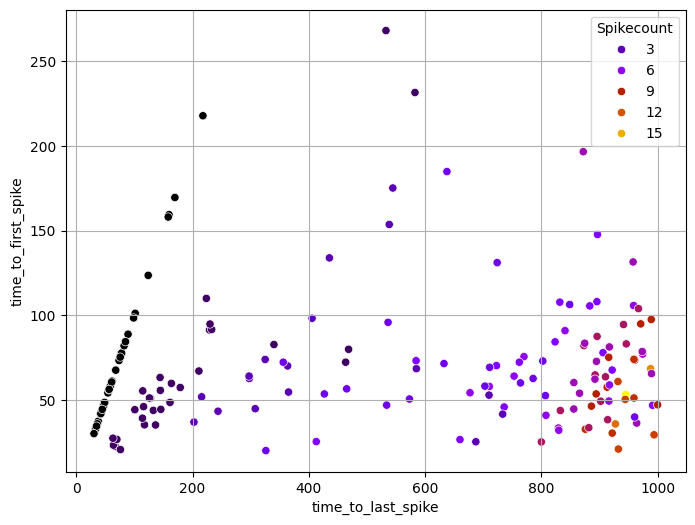

In [ ]:
#  'Spikecount', 'mean_frequency', 'time_to_first_spike',  'time_to_second_spike',  'time_to_last_spike'

aa = 'time_to_last_spike'
bb = 'time_to_first_spike'

plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_filtered, x=aa, y=bb, hue='Spikecount', palette='gnuplot')
plt.xlabel(aa)
plt.ylabel(bb)
plt.grid(True)
plt.show()


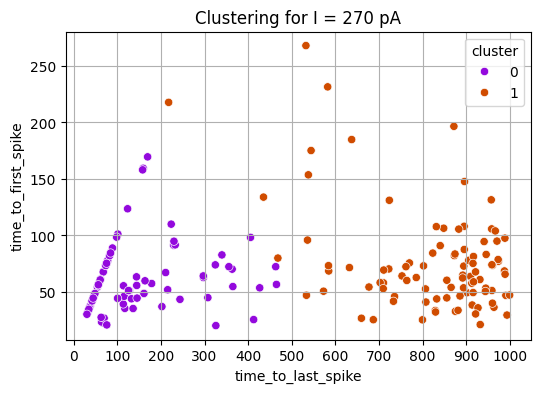

In [ ]:
# prompt: clustering the sccatter time_to_last_spike'  X 'time_to_first_spike'

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Prepare data for clustering
clustering_data = data_filtered[[aa, bb]].dropna() # Drop rows with NaN values
scaler = StandardScaler()
scaled_data = scaler.fit_transform(clustering_data)

# Determine optimal number of clusters (e.g., using Elbow method or visual inspection)
# For demonstration, let's assume 3 clusters
n_clusters = 2
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
clustering_data['cluster'] = kmeans.fit_predict(scaled_data)

# Add cluster labels back to the original filtered data
data_filtered2 = data_filtered.merge(clustering_data[['cluster']], left_index=True, right_index=True, how='left')


# Plot the clustered data
plt.figure(figsize=(6, 4))
sns.scatterplot(data=data_filtered2, x=aa, y=bb, hue='cluster', palette='gnuplot')
plt.title(f'Clustering for I = 270 pA')
plt.xlabel(aa)
plt.ylabel(bb)
plt.xticks(range(0,1100,100))
# plt.yticks(range(0,700,100))
plt.grid(True)
plt.show()


<Axes: xlabel='reobase', ylabel='Probability'>

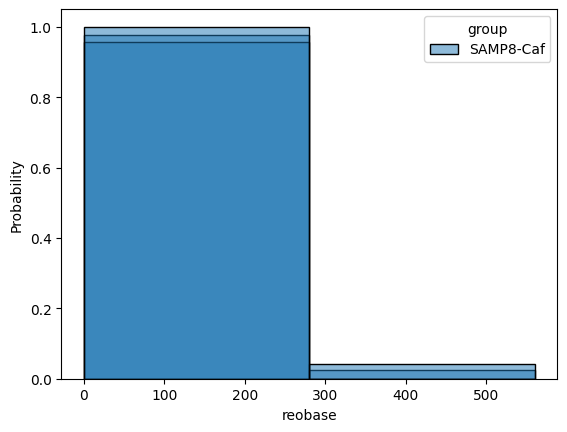

In [ ]:
sns.histplot(x='reobase', data=SAMP2, bins=range(0,800,280), alpha = 0.5, cumulative=False, hue='group', stat='probability')
sns.histplot(x='reobase', data=SAMP8, bins=range(0,800,280), alpha = 0.5, cumulative=False, hue='group', stat='probability')
sns.histplot(x='reobase', data=SAMP8_Caf, bins=range(0,800,280), alpha = 0.5, cumulative=False, hue='group', stat='probability')

In [ ]:
SAMP8.to_excel('Resultados_PAs_2026/SAMP8_passivas.xlsx')
SAMP8.get(SAMP8["current_pA"] == -110).to_excel('Resultados_PAs_2026/SAMP8_passivas_-110pA.xlsx')
SAMP8.get(SAMP8["current_pA"] == -90).to_excel('Resultados_PAs_2026/SAMP8_passivas_-90pA.xlsx')

SAMP8_Caf.to_excel('Resultados_PAs_2026/SAMP8_Caf_passivas.xlsx')
SAMP8_Caf.get(SAMP8_Caf["current_pA"] == -110).to_excel('Resultados_PAs_2026/SAMP8_Caf_passivas_-110pA.xlsx')
SAMP8_Caf.get(SAMP8_Caf["current_pA"] == -90).to_excel('Resultados_PAs_2026/SAMP8_Caf_passivas_-90pA.xlsx')

SAMP2.to_excel('Resultados_PAs_2026/SAMP2_passivas.xlsx')
SAMP2.get(SAMP2["current_pA"] == -110).to_excel('Resultados_PAs_2026/SAMP2_passivas_-110pA.xlsx')
SAMP2.get(SAMP2["current_pA"] == -90).to_excel('Resultados_PAs_2026/SAMP2_passivas_-90pA.xlsx')

In [ ]:
ls -li Resultados_PAs_2026/

total 787
3773 -rw------- 1 root root  17841 Mar 10 17:36 SAMP2_Electrophysiology_Data_onePercell.xlsx
3878 -rw------- 1 root root  15615 Mar 10 17:42 SAMP2_passivas_-110pA.xlsx
3881 -rw------- 1 root root  15588 Mar 10 17:42 SAMP2_passivas_-90pA.xlsx
3827 -rw------- 1 root root 192922 Mar 10 17:42 SAMP2_passivas.xlsx
3779 -rw------- 1 root root  19515 Mar 10 17:36 SAMP8_Caf_Electrophysiology_Data_onePercell.xlsx
3869 -rw------- 1 root root  17983 Mar 10 17:42 SAMP8_Caf_passivas_-110pA.xlsx
3872 -rw------- 1 root root  17932 Mar 10 17:42 SAMP8_Caf_passivas_-90pA.xlsx
3806 -rw------- 1 root root 221900 Mar 10 17:42 SAMP8_Caf_passivas.xlsx
3767 -rw------- 1 root root  20231 Mar 10 17:36 SAMP8_Electrophysiology_Data_onePercell.xlsx
3860 -rw------- 1 root root  18142 Mar 10 17:42 SAMP8_passivas_-110pA.xlsx
3863 -rw------- 1 root root  18105 Mar 10 17:42 SAMP8_passivas_-90pA.xlsx
3785 -rw------- 1 root root 226095 Mar 10 17:42 SAMP8_passivas.xlsx


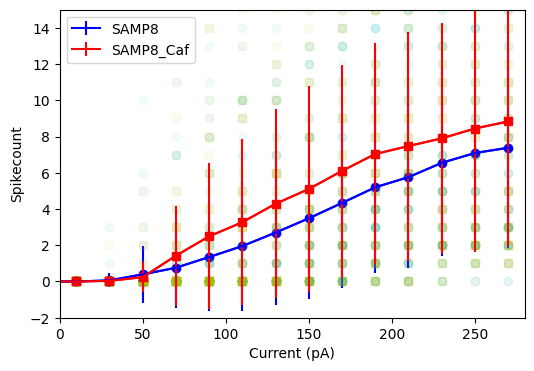

In [ ]:
for parameterName in  ['Spikecount']:

    plt.figure(figsize=(6, 4))

    Iinit = -110
    Ifinal = 270
    I_range = [j for j in range(Iinit,Ifinal+1,20)]
    Inumber = len(I_range)

    parameter = list(SAMP8[parameterName].get((SAMP8["current_pA"] >= Iinit) & (SAMP8["current_pA"] <= Ifinal)))

    VxI = []
    for i in range(NCells_SAMP8):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'co', alpha=0.05)
      VxI.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI, axis=0),'b-o')
    plt.errorbar(I_range, np.mean(VxI, axis=0), np.std(VxI, axis=0), color = "blue", label="SAMP8")


    parameter = list(SAMP8_Caf[parameterName].get((SAMP8_Caf["current_pA"] >= Iinit) & (SAMP8_Caf["current_pA"] <= Ifinal)))

    VxI2 = []
    for i in range(NCells_SAMP8_Caf):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'ys', alpha=0.05)
      VxI2.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI2, axis=0),'r-s')
    plt.errorbar(I_range, np.mean(VxI2, axis=0), np.std(VxI2, axis=0), color = "red", label="SAMP8_Caf")

    plt.xlabel('Current (pA)')
    plt.ylabel(parameterName)
    plt.xlim(0, Ifinal+10)
    plt.ylim(-2, 15)
    plt.legend();

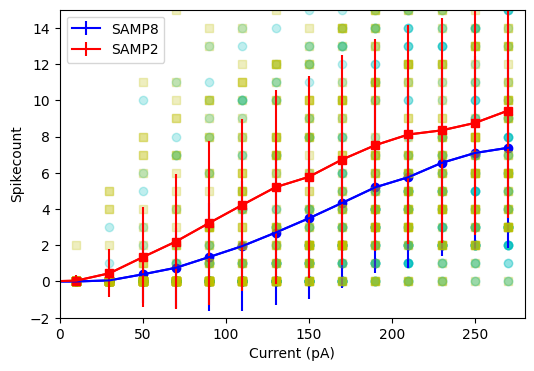

In [ ]:
for parameterName in  ['Spikecount']:

    plt.figure(figsize=(6, 4))

    Iinit = -110
    Ifinal = 270
    I_range = [j for j in range(Iinit,Ifinal+1,20)]
    Inumber = len(I_range)

    parameter = list(SAMP8[parameterName].get((SAMP8["current_pA"] >= Iinit) & (SAMP8["current_pA"] <= Ifinal)))

    VxI = []
    for i in range(NCells_SAMP8):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'co', alpha=0.25)
      VxI.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI, axis=0),'b-o')
    plt.errorbar(I_range, np.mean(VxI, axis=0), np.std(VxI, axis=0), color = "blue", label="SAMP8")


    parameter = list(SAMP2[parameterName].get((SAMP2["current_pA"] >= Iinit) & (SAMP2["current_pA"] <= Ifinal)))

    VxI2 = []
    for i in range(NCells_SAMP2):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'ys', alpha=0.25)
      VxI2.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI2, axis=0),'r-s')
    plt.errorbar(I_range, np.mean(VxI2, axis=0), np.std(VxI2, axis=0), color = "red", label="SAMP2")

    plt.xlabel('Current (pA)')
    plt.ylabel(parameterName)
    plt.xlim(0, Ifinal+10)
    plt.ylim(-2, 15)
    plt.legend();

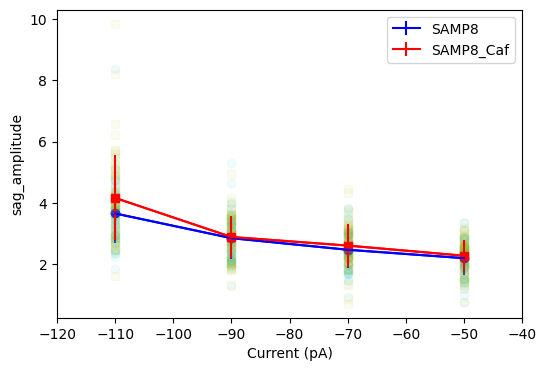

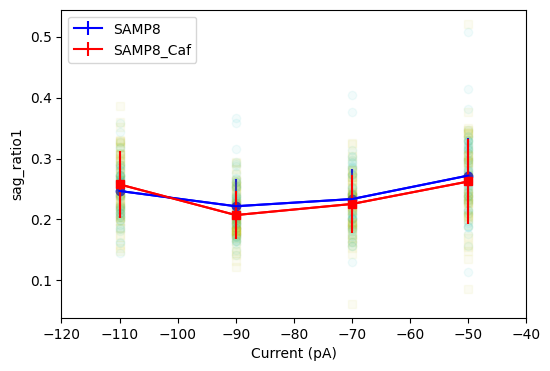

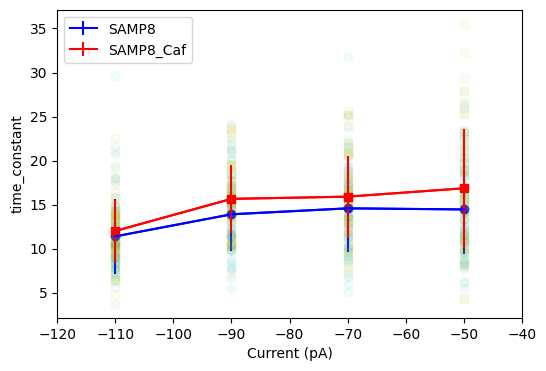

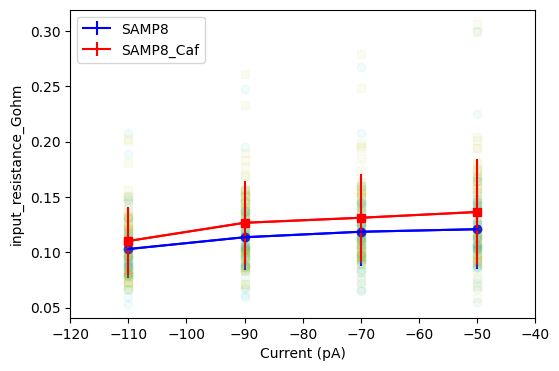

In [ ]:
for parameterName in  ["sag_amplitude", 'sag_ratio1', 'time_constant', 'input_resistance_Gohm']:

    plt.figure(figsize=(6, 4))

    Iinit = -110
    Ifinal = -50
    I_range = [j for j in range(Iinit,Ifinal+1,20)]
    Inumber = len(I_range)

    parameter = list(SAMP8[parameterName].get((SAMP8["current_pA"] >= Iinit) & (SAMP8["current_pA"] <= Ifinal)))

    VxI = []
    for i in range(NCells_SAMP8):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'co', alpha=0.05)
      VxI.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI, axis=0),'b-o')
    plt.errorbar(I_range, np.mean(VxI, axis=0), np.std(VxI, axis=0), color = "blue", label="SAMP8")


    parameter = list(SAMP8_Caf[parameterName].get((SAMP8_Caf["current_pA"] >= Iinit) & (SAMP8_Caf["current_pA"] <= Ifinal)))

    VxI2 = []
    for i in range(NCells_SAMP8_Caf):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'ys', alpha=0.05)
      VxI2.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI2, axis=0),'r-s')
    plt.errorbar(I_range, np.mean(VxI2, axis=0), np.std(VxI2, axis=0), color = "red", label="SAMP8_Caf")


    plt.xlabel('Current (pA)')
    plt.ylabel(parameterName)
    plt.xlim(Iinit-10, Ifinal+10)
    plt.legend();

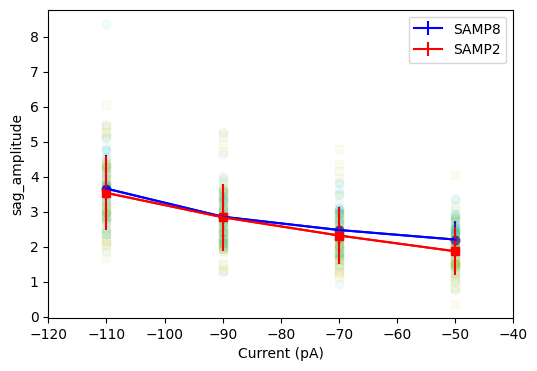

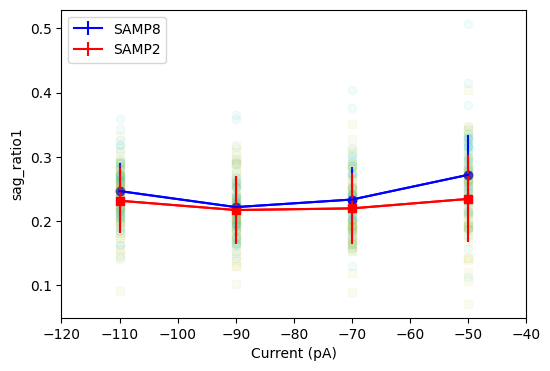

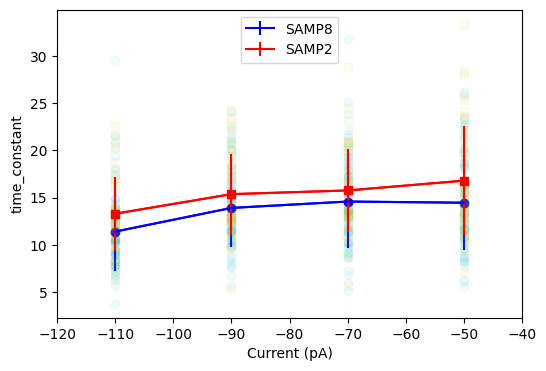

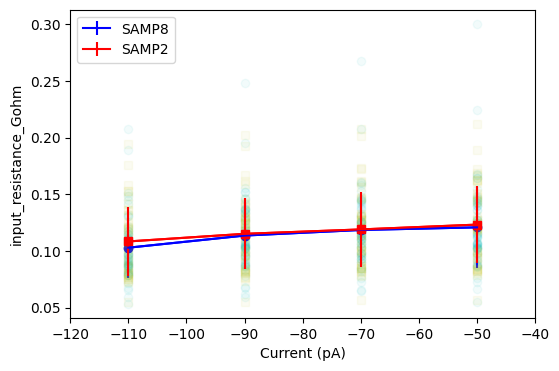

In [ ]:
for parameterName in  ["sag_amplitude", 'sag_ratio1', 'time_constant', 'input_resistance_Gohm']:

    plt.figure(figsize=(6, 4))

    Iinit = -110
    Ifinal = -50
    I_range = [j for j in range(Iinit,Ifinal+1,20)]
    Inumber = len(I_range)

    parameter = list(SAMP8[parameterName].get((SAMP8["current_pA"] >= Iinit) & (SAMP8["current_pA"] <= Ifinal)))

    VxI = []
    for i in range(NCells_SAMP8):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'co', alpha=0.05)
      VxI.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI, axis=0),'b-o')
    plt.errorbar(I_range, np.mean(VxI, axis=0), np.std(VxI, axis=0), color = "blue", label="SAMP8")


    parameter = list(SAMP2[parameterName].get((SAMP2["current_pA"] >= Iinit) & (SAMP2["current_pA"] <= Ifinal)))

    VxI2 = []
    for i in range(NCells_SAMP2):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'ys', alpha=0.05)
      VxI2.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI2, axis=0),'r-s')
    plt.errorbar(I_range, np.mean(VxI2, axis=0), np.std(VxI2, axis=0), color = "red", label="SAMP2")



    plt.xlabel('Current (pA)')
    plt.ylabel(parameterName)
    plt.xlim(Iinit-10, Ifinal+10)
    plt.legend();

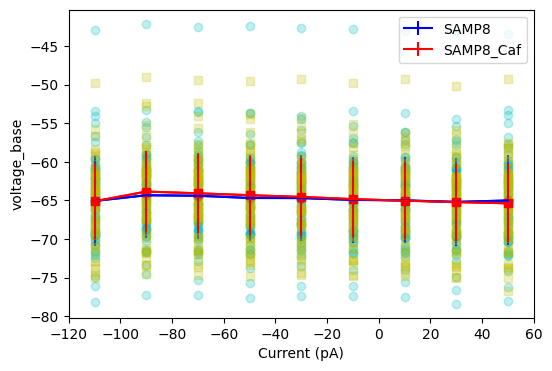

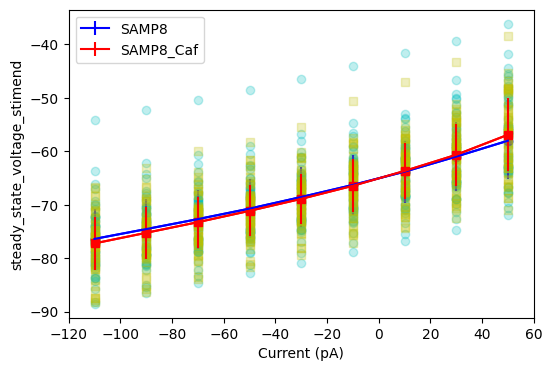

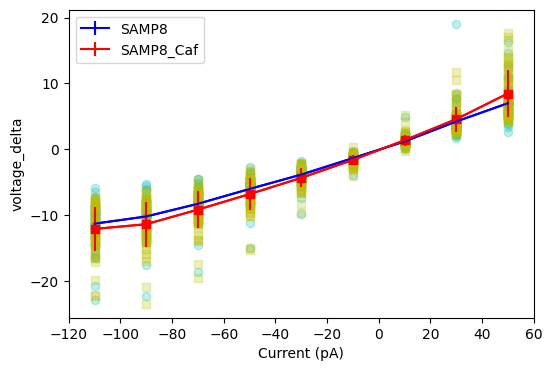

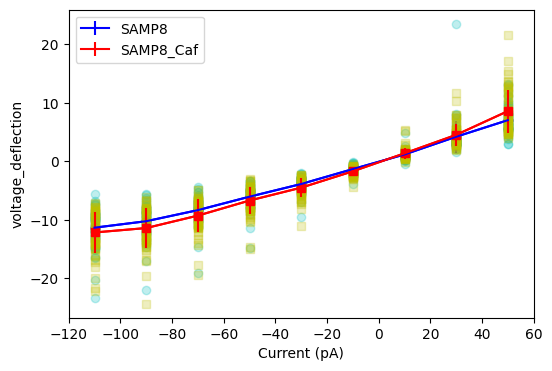

In [ ]:
for parameterName in  ["voltage_base", 'steady_state_voltage_stimend', 'voltage_delta', 'voltage_deflection']:

    plt.figure(figsize=(6, 4))

    Iinit = -110
    Ifinal = 50
    I_range = [j for j in range(Iinit,Ifinal+1,20)]
    Inumber = len(I_range)

    parameter = list(SAMP8[parameterName].get((SAMP8["current_pA"] >= Iinit) & (SAMP8["current_pA"] <= Ifinal)))

    VxI = []
    for i in range(NCells_SAMP8):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'co', alpha=0.25)
      VxI.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI, axis=0),'b-o')
    plt.errorbar(I_range, np.mean(VxI, axis=0), np.std(VxI, axis=0), color = "blue", label="SAMP8")


    parameter = list(SAMP8_Caf[parameterName].get((SAMP8_Caf["current_pA"] >= Iinit) & (SAMP8_Caf["current_pA"] <= Ifinal)))

    VxI2 = []
    for i in range(NCells_SAMP8_Caf):
      plt.plot(I_range,parameter[i*Inumber:(i+1)*Inumber],'ys', alpha=0.25)
      VxI2.append(np.array(parameter[i*Inumber:(i+1)*Inumber]))

    plt.plot(I_range, np.mean(VxI2, axis=0),'r-s')
    plt.errorbar(I_range, np.mean(VxI2, axis=0), np.std(VxI2, axis=0), color = "red", label="SAMP8_Caf")

    plt.xlabel('Current (pA)')
    plt.ylabel(parameterName)
    plt.xlim(Iinit-10, Ifinal+10)
    plt.legend();

In [ ]:
# table.keys() # 'current_pA', 'Spikecount', 'mean_frequency', 'reobase',

medidas = ['voltage_base', 'steady_state_voltage_stimend', 'voltage_delta',
           'voltage_deflection', 'time_constant', 'decay_time_constant_after_stim',
           'capacitance_pF', 'sag_amplitude', 'input_resistance_Gohm']

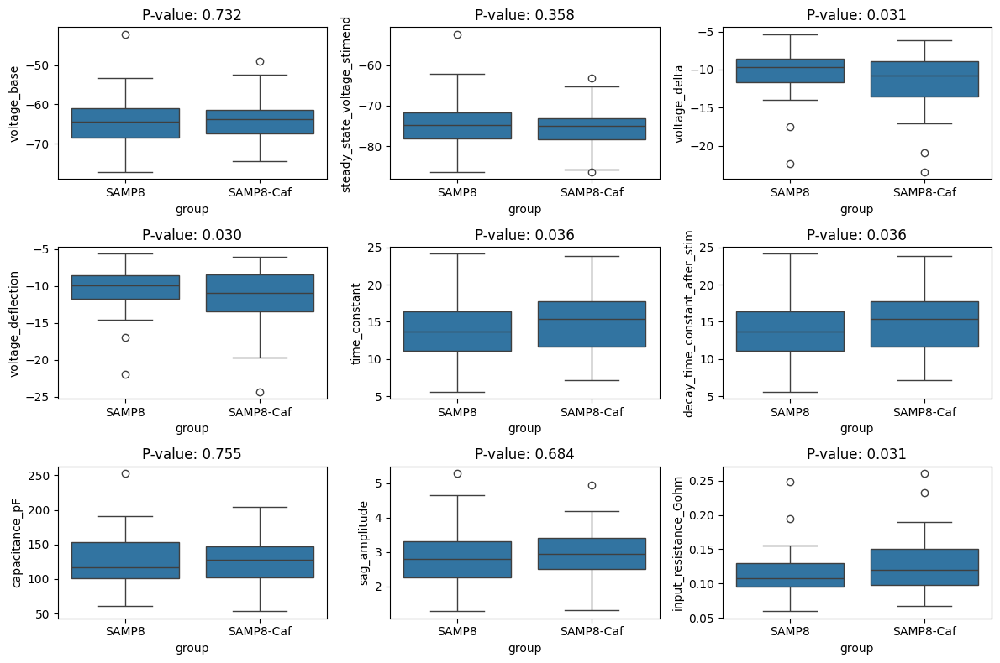

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 8))

table2 = table[table['current_pA'] == -90]
data_filtered = table2[table2['group'].isin(['SAMP8','SAMP8-Caf'])]

for i, medida in enumerate(medidas):


    # Perform t-test
    control_data = data_filtered[data_filtered['group'] == 'SAMP8'][medida].astype(float) # Convert to numeric type
    Caf_data = data_filtered[data_filtered['group'] == 'SAMP8-Caf'][medida].astype(float) # Convert to numeric type
    t_stat, p_value = stats.ttest_ind(control_data, Caf_data)

    # print(f"T-statistic: {t_stat:.2f}")
    # print(f"P-value: {p_value:.3f}")

    # plt.title(f"Mean {medida}, P-value: {p_value:.3f}")
    # Create boxplot
    row = i // 3  # Calculate the row index
    col = i % 3   # Calculate the column index
    ax = axes[row, col]  # Access the correct Axes object using row and column indices
    ax.set_title(f"P-value: {p_value:.3f}")
    sns.boxplot(x='group', y=medida, data=data_filtered, ax = ax)

plt.tight_layout()
plt.show()

In [ ]:
# table.keys() # 'current_pA', 'Spikecount', 'mean_frequency', 'reobase',

medidas = ['voltage_base', 'steady_state_voltage_stimend', 'voltage_delta',
           'voltage_deflection', 'time_constant', 'decay_time_constant_after_stim',
           'capacitance_pF', 'sag_amplitude', 'input_resistance_Gohm']

medidas = ['voltage_base', 'steady_state_voltage_stimend', 'voltage_delta', 'reobase', 'mean_frequency', 'Spikecount']

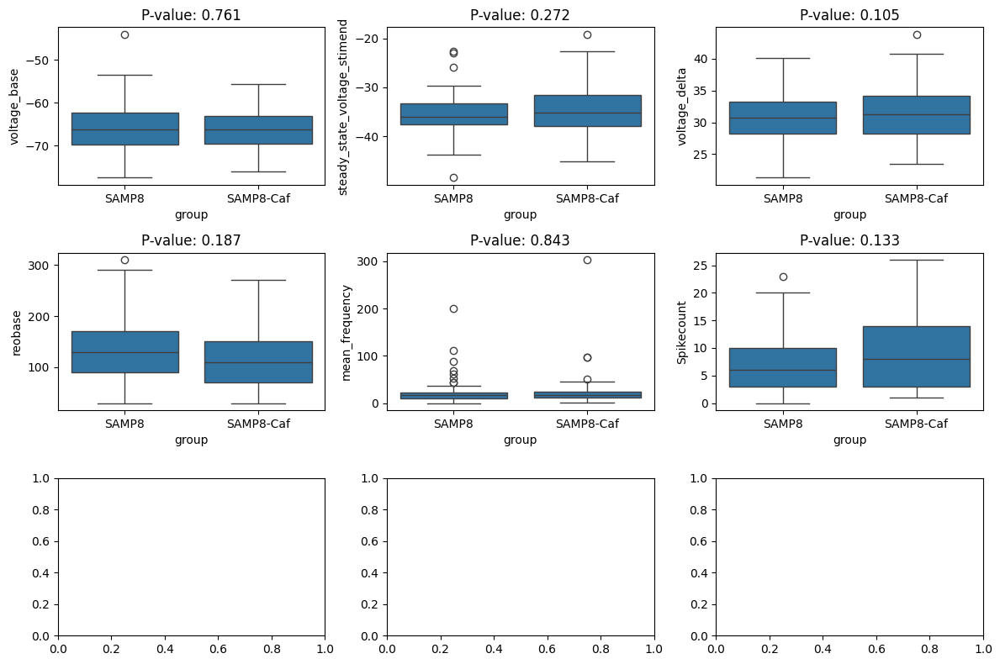

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 8))

table2 = table[table['current_pA'] == 270]
data_filtered = table2[table2['group'].isin(['SAMP8','SAMP8-Caf'])]

for i, medida in enumerate(medidas):


    # Perform t-test
    control_data = data_filtered[data_filtered['group'] == 'SAMP8'][medida].astype(float) # Convert to numeric type
    Caf_data = data_filtered[data_filtered['group'] == 'SAMP8-Caf'][medida].astype(float) # Convert to numeric type
    t_stat, p_value = stats.ttest_ind(control_data, Caf_data)

    # print(f"T-statistic: {t_stat:.2f}")
    # print(f"P-value: {p_value:.3f}")

    # plt.title(f"Mean {medida}, P-value: {p_value:.3f}")
    # Create boxplot
    row = i // 3  # Calculate the row index
    col = i % 3   # Calculate the column index
    ax = axes[row, col]  # Access the correct Axes object using row and column indices
    ax.set_title(f"P-value: {p_value:.3f}")
    sns.boxplot(x='group', y=medida, data=data_filtered, ax = ax)

plt.tight_layout()
plt.show()

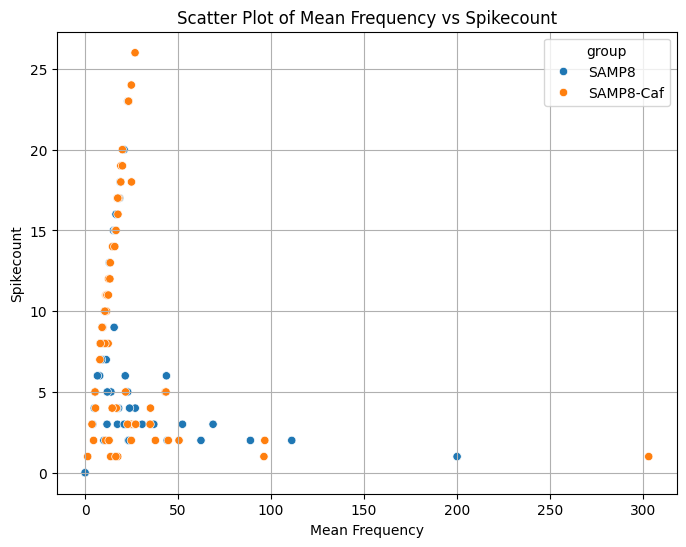

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_filtered, x='mean_frequency', y='Spikecount', hue='group')
plt.title('Scatter Plot of Mean Frequency vs Spikecount')
plt.xlabel('Mean Frequency')
plt.ylabel('Spikecount')
plt.grid(True)
plt.show()

## Simgle cell review

In [ ]:
ListaFiles[39:43]

['50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 30/26305000.abf',
 '50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 31/26305008.abf',
 '50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 32/26305019.abf',
 '50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 33/26305032.abf']

In [ ]:
abfnames[602:700:10]

['Cell 30/26305000.abf',
 'Cell 30/26305000.abf',
 'Cell 30/26305000.abf',
 'Cell 31/26305008.abf',
 'Cell 31/26305008.abf',
 'Cell 32/26305019.abf',
 'Cell 32/26305019.abf',
 'Cell 32/26305019.abf',
 'Cell 33/26305032.abf',
 'Cell 33/26305032.abf']

In [ ]:
abf = pyabf.ABF('50-70 dias de idade SAMP-8 controle/Cell HPC/Cell 30/26305000.abf')

In [ ]:
# Update: It is more convenient to set all the input parameters at the beginning
sweeps = abf.sweepList[0:15]     # Remove the square brackets if you want to select all the sweeps
stim_start = 223.4              # beginning of the current stimulus in miliseconds
stim_end = 1223.4                     # end of the current stimulus in miliseconds
sampling_freq = 20000
currentstep_time = int(0.4 * sampling_freq) # type a time point (s) within a current step
# Define the range of current steps to calculate the input resistance from
ir_current_begin = -110           # current step in pA
ir_current_end = 170               # current step in pA

# Set the columns of the output table
table = pd.DataFrame(columns=['voltage',
                              'steady_state_voltage_stimend',
                              'voltage_delta',
                              'current_pA',
                              'input_resistance_Gohm',
                              'time_constant',
                              'capacitance_pF',
                              'sag_amplitude',
                              'sag_ratio1'])

# Loop function
for sweep in sweeps:  # To select a ranfe of traces
    abf.setSweep(sweep)
    # Defines a trace and region of analysis
    trace = {'T': abf.sweepX*1000, # convert to ms
             'V': abf.sweepY,
             'I': (-110+20*sweep + abf.sweepC),
             'stim_start' : [stim_start],
             'stim_end' : [stim_end]}
    traces = [trace]

    # Optional: You can adjust the parameters for the calculation of the time constant
    # efel.api.setDoubleSetting('decay_start_after_stim', 0)  # default = 1 ms
    # efel.api.setDoubleSetting('decay_end_after_stim', 30)  # default = 10 ms

    # Output features
    feature_values = efel.get_feature_values(traces,
                                           ['voltage','voltage_base',
                                            'steady_state_voltage_stimend',
                                            'current',
                                            'decay_time_constant_after_stim',
                                            'sag_amplitude',
                                            'sag_ratio1'],
                                           raise_warnings=None)[0] # If true, returns warnings

    # Create table from the results
    # Use [0] to extract the values from the Spikecount array
    length = len(table)
    table.loc[length, 'voltage'] = feature_values['voltage'][0]
    table.loc[length, 'steady_state_voltage_stimend'] = feature_values['steady_state_voltage_stimend'][0]
    table.loc[length, 'voltage_delta'] = (feature_values['steady_state_voltage_stimend']
                                          - feature_values['voltage'])[0]
    table.loc[length, 'current_pA'] = feature_values['current'][currentstep_time] # [:] current step
    table.loc[length, 'sag_amplitude'] = feature_values['sag_amplitude']
    table.loc[length, 'sag_ratio1'] = feature_values['sag_ratio1']

    if (table.loc[length, 'current_pA']  >= ir_current_begin) & (table.loc[length, 'current_pA']  < ir_current_end):
        table.loc[length, 'input_resistance_Gohm'] = (table.loc[length, 'voltage_delta']
                                                      /table.loc[length, 'current_pA'])
        if (feature_values['decay_time_constant_after_stim'] is not None):
            table.loc[length, 'time_constant'] = feature_values['decay_time_constant_after_stim'][0]
            table.loc[length, 'capacitance_pF'] = (feature_values['decay_time_constant_after_stim']
                                                   /table.loc[length, 'input_resistance_Gohm'])[0]

In [ ]:
table

,voltage,steady_state_voltage_stimend,voltage_delta,current_pA,input_resistance_Gohm,time_constant,capacitance_pF,sag_amplitude,sag_ratio1
0,-61.645508,-78.656268,-17.01076,-220.0,NaN,NaN,NaN,4.137921404753641,0.19219801378496162
1,-61.279297,-76.758599,-15.479302,-180.0,NaN,NaN,NaN,2.7091743705188662,0.15270053041447265
2,-61.61499,-73.979213,-12.364223,-140.0,NaN,NaN,NaN,2.4978378554755096,0.17186495612998753
3,-61.889648,-71.135133,-9.245485,-100.0,0.092455,15.050613,162.78879,1.4051500257499896,0.1401185489866877
4,-62.438965,-67.560461,-5.121496,-60.0,0.085358,16.623495,194.749678,1.3177130486689066,0.20367797384650202
5,-61.859131,-63.742715,-1.883584,-20.0,0.094179,60.603553,643.491922,0.9240332408974865,0.2888969442394535
6,-61.920166,-60.002741,1.917425,20.0,0.095871,21.479951,224.050019,None,None
7,-62.561035,-55.298614,7.262421,60.0,0.12104,21.632857,178.724329,None,None
8,-62.103271,-49.160251,12.94302,100.0,0.12943,22.010465,170.05664,None,None
9,-61.126709,-45.870816,15.255893,140.0,0.108971,16.039685,147.192686,None,None


Input resitance (GOhm) = 0.15996890247029508


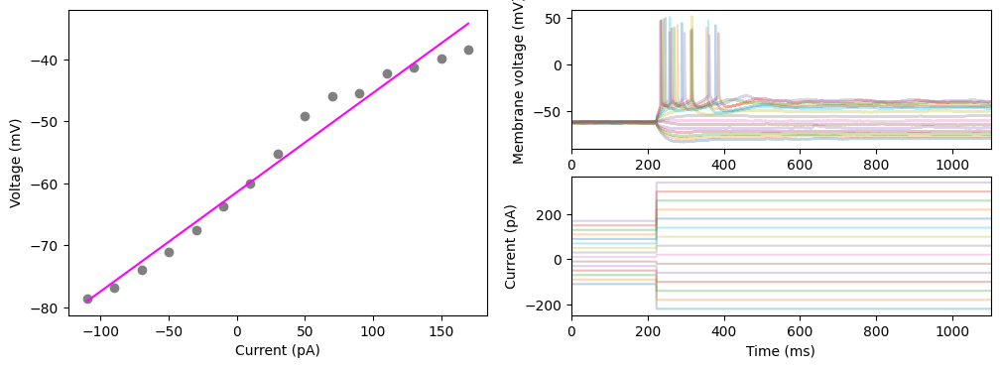

,voltage,steady_state_voltage_stimend,voltage_delta,current_pA,input_resistance_Gohm,time_constant,capacitance_pF,sag_amplitude,sag_ratio1
0,-61.645508,-78.656268,-17.01076,-220.0,NaN,NaN,NaN,4.137921404753641,0.19219801378496162
1,-61.279297,-76.758599,-15.479302,-180.0,NaN,NaN,NaN,2.7091743705188662,0.15270053041447265
2,-61.61499,-73.979213,-12.364223,-140.0,NaN,NaN,NaN,2.4978378554755096,0.17186495612998753
3,-61.889648,-71.135133,-9.245485,-100.0,0.092455,15.050613,162.78879,1.4051500257499896,0.1401185489866877
4,-62.438965,-67.560461,-5.121496,-60.0,0.085358,16.623495,194.749678,1.3177130486689066,0.20367797384650202
5,-61.859131,-63.742715,-1.883584,-20.0,0.094179,60.603553,643.491922,0.9240332408974865,0.2888969442394535
6,-61.920166,-60.002741,1.917425,20.0,0.095871,21.479951,224.050019,None,None
7,-62.561035,-55.298614,7.262421,60.0,0.12104,21.632857,178.724329,None,None
8,-62.103271,-49.160251,12.94302,100.0,0.12943,22.010465,170.05664,None,None
9,-61.126709,-45.870816,15.255893,140.0,0.108971,16.039685,147.192686,None,None


In [ ]:
ir_index_begin = 0               # index (position) of the current step
ir_index_end = 15                # index (position) of the current step

# Optional plotting: example with three subplots
fig = plt.figure(figsize=(12, 4))
fig.tight_layout()

# I-V curve plot
ax1 = fig.add_subplot(1, 2, 1)
# Get current value from a time point within current step
currents = []
for sweep in sweeps:
    abf.setSweep(sweep)
    currents.append((-110+20*sweep))
x = currents
y = table.loc[:,'steady_state_voltage_stimend']
y_list = y.values.tolist()
x_ir = x[ir_index_begin:ir_index_end]
y_ir = y_list[ir_index_begin:ir_index_end]
m, b = np.polyfit(x_ir, y_ir, 1)
line = np.polyval([m, b], x_ir)
ax1.plot(x_ir, line, color='magenta')
ax1.scatter(x, y, color='gray')
ax1.set_xlabel('Current (pA)')
ax1.set_ylabel('Voltage (mV)')

# Voltage traces plot
ax2 = fig.add_subplot(2, 2, 2)
for sweep in sweeps:
    abf.setSweep(sweep)
    ax2.plot(abf.sweepX*1000, abf.sweepY, alpha=0.3)
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Membrane voltage (mV)')
ax2.axes.set_xlim(0, 1100)  # set the x-axis range if necessary

# Current steps plot
ax3 = fig.add_subplot(2, 2, 4, sharex=ax2)
for sweep in sweeps:
    abf.setSweep(sweep)
    ax3.plot(abf.sweepX*1000, (-110+20*sweep + abf.sweepC), alpha=0.3)
ax3.set_xlabel('Time (ms)')
ax3.set_ylabel('Current (pA)')
ax3.axes.set_xlim(0, 1100)  # set the x-axis range if necessary

# Display the graph and the table
print ("Input resitance (GOhm) =", m)
plt.show()
table